# Offline replay: can PRIME adapt to a new TEP baseline window?

This notebook replays one closed-loop PRIME session offline and changes one thing: the baseline window of the
TEP. Everything else is the online code in `prime/decider/prime_core`, imported read-only. The new window is
set on the notebook's own `Preprocessor` objects; no file in `prime/` is modified.

The replay runs in two arms with identical code:

- **control**: the online baseline [−25, −15] ms on the online post buffer [−30, 100] ms. It has to reproduce
  what the online system computed. Whatever it does not reproduce is replay noise, not an effect of the baseline.
- **new**: `BASELINE` on a [−200, 100] ms buffer stitched from `_pre_raw` and `_post_raw`.

| section | content |
|---|---|
| 0 | parameters |
| 1 | setup, completeness check |
| 2 | new raw buffers [−200, 100] ms |
| 3 | calibration replay and all calibration outcomes |
| 4 | continual adaptation through the intervention blocks |
| 5 | calibration compared with the online calibration |
| 6 | rejections compared with the online rejections |
| 7 | prediction performance |
| 8 | out-of-sample test on the evaluation blocks |

**What the replay cannot change.** Every pulse happens where it happened online, on a trial the online model
and threshold chose. The replay tests what the re-calibrated model predicts and learns on those trials, not
which trials it would have selected. The QC history before each trigger (the 10 ms windows of
`process_periodic`) was not saved, so only the window that triggered a pulse is gated again.

**Requirements.** CUDA (`OnlinePredictor` hard-codes it; `ALLOW_CPU` is a fallback), `torch`, `mne`,
`mne-icalabel`. A few minutes per session.

## 0 · Parameters

All paths follow from `SUBJECT_ID`. `RUN_ID = None` picks the run folder that holds
`prime/trials_intervention.csv`. Output folders are created when missing.

In [30]:
# ---------------------------------------------------------------- session
SUBJECT_ID = "pilot005"          # BIDS subject label, without "sub-"
SESSION_ID = "ses-prime"
RUN_ID     = None                # NeuroSimo run folder, e.g. "105"; None = the one folder with prime/trials_intervention.csv

# ---------------------------------------------------------------- what changes
BASELINE   = (-0.165, -0.066)    # s, new TEP baseline window (online: -0.025, -0.015)
RAW_WINDOW = (-0.200, 0.100)     # s, new raw buffer stitched from _pre_raw + _post_raw; must contain BASELINE

# ---------------------------------------------------------------- arms and outputs
RUN_CONTROL   = True             # also replay with the online baseline (validation and reference)
OVERWRITE_RAW = False            # rewrite new raw buffers that already exist
NEW_RAW_DIR   = None             # None: BIDS/sub-<ID>/<SESSION>/<RUN>/new_raw_trial
RESULTS_ROOT  = None             # None: <Loop>/offline_baseline/sub-<ID>, one folder per arm below it

# ---------------------------------------------------------------- decider settings that changed between sessions
SESSION_OVERRIDES = {
    "pilot003": {"ocular_z_threshold": 2.0},   # ran before commit f4fd395 (2026-09-17: 2.0 -> 2.5)
    "pilot004": {"ocular_z_threshold": 2.0},
}

ALLOW_CPU = False                # OnlinePredictor hard-codes CUDA; True runs it on the CPU when there is no GPU

## 1 · Setup and completeness check

### 1.1 Setup

`prime/decider` goes on `sys.path` with `sys.dont_write_bytecode = True`, so Python does not even write
`__pycache__` files into `prime/`. Three things are adapted in memory, never on disk:

- **`np.trapz`**: NumPy 2.4 removed it, and the bad-channel check in `Preprocessor.calibrate()` still calls it.
  `np.trapezoid` is the same function under its new name.
- **CUDA**: `OnlinePredictor` calls `torch.device("cuda")`. With `ALLOW_CPU = True` and no GPU, its module sees
  a `torch` whose `device()` returns the CPU; predictions then differ from a GPU run in the last digits.
- **session settings**: `SESSION_OVERRIDES` (ocular z threshold 2.0 for pilot003/004, which ran before
  commit `f4fd395`).

`SEED` and the model file names are read from `2_intervention.py` itself, without importing it (it loads the
TMS driver).

In [31]:
import ast, contextlib, io, json, os, platform, sys, textwrap, time, types, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)

# conditions: the colours of PRIME_online_performance.ipynb and early_baseline_check.ipynb
COLOR_PREDETERMINED = "#5b8ff9"
COLOR_PRIME_SINGLE  = "#e8684a"
CONDITION_COLORS = {"predetermined_single": COLOR_PREDETERMINED, "prime_single_pulse": COLOR_PRIME_SINGLE}
# data sources: the online log (grey, dashed, open markers), the control replay, the new-baseline replay
SOURCE_STYLE = {
    "online":  dict(color="#595959", ls="--", marker="o", mfc="white"),
    "control": dict(color="#199e70", ls="-",  marker="s", mfc="#199e70"),
    "new":     dict(color="#4a3aa7", ls="-",  marker="D", mfc="#4a3aa7"),
}

if not hasattr(np, "trapz"):     # NumPy >= 2.4 removed np.trapz; Preprocessor.calibrate() still calls it
    np.trapz = np.trapezoid      # (bad-channel AUC). Same function, new name; in memory only.


def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError("Loop root not found; set the LOOP_ROOT environment variable.")


# ---------------------------------------------------------------- paths, all derived from SUBJECT_ID
LOOP_ROOT    = _find_loop_root()
PRIME_DIR    = LOOP_ROOT / "prime"
DECIDER_DIR  = PRIME_DIR / "decider"
FORWARD_PATH = PRIME_DIR / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
SESSION_DIR  = LOOP_ROOT / "BIDS" / f"sub-{SUBJECT_ID}" / SESSION_ID
if RUN_ID is None:
    runs = sorted({p.parent.parent.name for p in SESSION_DIR.glob("*/prime/trials_intervention.csv")})
    if len(runs) != 1:
        raise FileNotFoundError(f"expected one run folder with prime/trials_intervention.csv in {SESSION_DIR}, "
                                f"found {runs}; set RUN_ID")
    RUN_ID = runs[0]
ONLINE_DIR   = SESSION_DIR / RUN_ID / "prime"             # everything the online decider wrote
NEW_RAW_DIR  = Path(NEW_RAW_DIR) if NEW_RAW_DIR else SESSION_DIR / RUN_ID / "new_raw_trial"
RESULTS_ROOT = Path(RESULTS_ROOT) if RESULTS_ROOT else LOOP_ROOT / "offline_baseline" / f"sub-{SUBJECT_ID}"
for p in (ONLINE_DIR, DECIDER_DIR, FORWARD_PATH):
    if not p.exists():
        raise FileNotFoundError(p)
for p in (NEW_RAW_DIR, RESULTS_ROOT):                     # outputs never go into prime/
    if p.resolve().is_relative_to(PRIME_DIR.resolve()):
        raise ValueError(f"output folder inside prime/: {p}")

# ---------------------------------------------------------------- the online code, read-only
sys.dont_write_bytecode = True                            # no __pycache__ written into prime/
if str(DECIDER_DIR) not in sys.path:
    sys.path.insert(0, str(DECIDER_DIR))
import mne
import torch
try:
    import mne_icalabel
except ImportError as err:
    raise ImportError("the calibration replay needs mne-icalabel: pip install mne-icalabel") from err
import prime_core.online_predictor as online_predictor_module
from prime_core.online_predictor import OnlinePredictor
from prime_core.tep_normalizer import TEPNormalizer
from prime_core.preprocessing.preprocessor import (
    Preprocessor, crop_eeg_buffer, _butter_filter, _interpolate_bad_channels,
    _detect_bad_channels_qc, _detect_bad_channels_post,
)
from prime_core.preprocessing.dipole_fitter import DipoleFitter
from prime_core.preprocessing.config import get_default_config
from prime_core.preprocessing.utils.mad import global_mad_zscore_rejected, local_mad_zscore_rejected
from prime_core.prime_config import (
    get_raw_sfreq, get_processed_sfreq, get_calibration_time_range, get_qc_time_range,
    get_model_time_range, get_post_initial_time_range, get_post_time_range, get_dipole_time_range,
)
mne.set_log_level("ERROR")
import logging
logging.getLogger("prime_core.models.s4").setLevel(logging.WARNING)   # "Constructing S4 ..." messages

# constants of the decider, read from 2_intervention.py without importing it
DECIDER_SRC = (DECIDER_DIR / "2_intervention.py").read_text(encoding="utf-8")


def decider_constant(name):
    for node in ast.parse(DECIDER_SRC).body:
        if isinstance(node, ast.Assign) and any(getattr(t, "id", None) == name for t in node.targets):
            try:
                return ast.literal_eval(node.value)
            except ValueError:
                return ast.get_source_segment(DECIDER_SRC, node.value)
    raise KeyError(f"{name} not found in 2_intervention.py")


SEED         = decider_constant("SEED")                        # seed of the online OnlinePredictor
BLOCK_TRIALS = decider_constant("INTERVENTION_BLOCK_TRIALS")   # intervention trials per block (checked in 1.2)
PRETRAINED_PATH   = DECIDER_DIR / "offline_results" / "train" / "pretrained_all.pt"
BACKROTATION_PATH = DECIDER_DIR / "offline_results" / "train" / "global_backrotation_all.npy"
for const, path in (("PRETRAINED_MODEL_PATH", PRETRAINED_PATH), ("GLOBAL_BACKROTATION_PATH", BACKROTATION_PATH)):
    if path.name not in decider_constant(const):
        raise ValueError(f"2_intervention.py: {const} = {decider_constant(const)}, not {path.name}")

# ---------------------------------------------------------------- GPU, or the CPU fallback
if torch.cuda.is_available():
    DEVICE_NOTE = f"CUDA, {torch.cuda.get_device_name(0)}"
elif ALLOW_CPU:
    class _CPUTorch(types.ModuleType):
        # OnlinePredictor calls torch.device("cuda"); this answers with the CPU. Only its module sees it.
        def __getattr__(self, name):
            return getattr(torch, name)

        @staticmethod
        def device(*args, **kwargs):
            return torch.device("cpu")

    online_predictor_module.torch = _CPUTorch("torch")
    DEVICE_NOTE = "CPU (ALLOW_CPU; predictions differ from a GPU run in the last digits)"
else:
    raise RuntimeError("OnlinePredictor needs CUDA: run on the GPU machine or set ALLOW_CPU = True")

# ---------------------------------------------------------------- time windows (configs/prime.yaml)
RAW_SFREQ, PROC_SFREQ    = get_raw_sfreq(), get_processed_sfreq()   # 5000 / 1000 Hz
CAL_TMIN, CAL_TMAX       = get_calibration_time_range()             # _trial_raw.npy [-1100, 100] ms
QC_TMIN, QC_TMAX         = get_qc_time_range()                      # _pre_raw.npy   [-210, -10] ms
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()            # _post_raw.npy  [-30, 100] ms
POST_TMIN, POST_TMAX     = get_post_time_range()                    # processed post epoch [1, 100] ms
DIP_TMIN, DIP_TMAX       = get_dipole_time_range()                  # dipole window [38, 50] ms
MODEL_TMIN, MODEL_TMAX   = get_model_time_range()                   # model window [-65, -15] ms
DEFAULT_CFG              = get_default_config()
ONLINE_BASELINE          = tuple(DEFAULT_CFG.baseline)              # [-25, -15] ms
ARTIFACT_START           = DEFAULT_CFG.artifact_window_1[0]         # -14 ms
OVERRIDES                = SESSION_OVERRIDES.get(SUBJECT_ID, {})

ms = lambda w: f"[{w[0] * 1e3:.0f}, {w[1] * 1e3:.0f}] ms"
if not (QC_TMIN <= RAW_WINDOW[0] and np.isclose(RAW_WINDOW[1], POST_I_TMAX)):
    raise ValueError(f"RAW_WINDOW must start at or after {QC_TMIN * 1e3:.0f} ms and end at {POST_I_TMAX * 1e3:.0f} ms")
if not (RAW_WINDOW[0] + 0.010 <= BASELINE[0] < BASELINE[1] <= ARTIFACT_START):
    raise ValueError(f"BASELINE must lie within {ms((RAW_WINDOW[0] + 0.010, ARTIFACT_START))}: 10 ms from the "
                     "buffer start (resampling filter) and before the artifact window")


def git_head(repo: Path) -> str:
    # Commit of the prime repository, read from .git without running git.
    git = repo / ".git"
    try:
        head = (git / "HEAD").read_text().strip()
        if not head.startswith("ref:"):
            return head
        ref = head.split(maxsplit=1)[1]
        if (git / ref).is_file():
            return (git / ref).read_text().strip()
        for line in (git / "packed-refs").read_text().splitlines():
            if line.endswith(" " + ref):
                return line.split()[0]
    except OSError:
        pass
    try:                                                   # last entry of the reflog
        return (git / "logs" / "HEAD").read_text().strip().splitlines()[-1].split()[1]
    except (OSError, IndexError):
        return "unknown"


PRIME_COMMIT = git_head(DECIDER_DIR)
print(f"session         : {ONLINE_DIR.relative_to(LOOP_ROOT)}")
print(f"baselines       : new {ms(BASELINE)} on {ms(RAW_WINDOW)}; online {ms(ONLINE_BASELINE)} on "
      f"{ms((POST_I_TMIN, POST_I_TMAX))}")
print(f"new raw buffers : {NEW_RAW_DIR}")
print(f"results         : {RESULTS_ROOT}")
print(f"overrides       : {OVERRIDES or 'none'}")
print(f"prime commit    : {PRIME_COMMIT[:10]}, SEED {SEED}")
print(f"device          : {DEVICE_NOTE}")
print(f"versions        : python {platform.python_version()}, numpy {np.__version__}, scipy {scipy.__version__}, "
      f"mne {mne.__version__}, mne-icalabel {mne_icalabel.__version__}, torch {torch.__version__}")

session         : BIDS\sub-pilot005\ses-prime\105\prime
baselines       : new [-165, -66] ms on [-200, 100] ms; online [-25, -15] ms on [-30, 100] ms
new raw buffers : D:\Linus\Loop\BIDS\sub-pilot005\ses-prime\105\new_raw_trial
results         : D:\Linus\Loop\offline_baseline\sub-pilot005
overrides       : none
prime commit    : f4fd3954c4, SEED 201
device          : CUDA, NVIDIA GeForce RTX 4090
versions        : python 3.11.9, numpy 2.3.2, scipy 1.16.1, mne 1.10.0, mne-icalabel 0.7.0, torch 2.7.0+cu128


### 1.2 The online session

`trials_intervention.csv` defines the replay: 125 calibration trials and 800 intervention trials in session
order. `g` is the intervention trial index the decider counts; the online checkpoints are named after it
(`classifier_after_trial_<g>.pt`). `lat_ms` is the trigger-to-pulse latency of PRIME trials, which decides where
the prediction window comes from (section 4). The evaluation tables list the open-loop trials of
section 8 (the baseline block is not used).

In [32]:
TRIALS = pd.read_csv(ONLINE_DIR / "trials_intervention.csv")
TRIALS["stem"] = TRIALS.stage + "_" + TRIALS.trial_in_stage.map("{:04d}".format)
TRIALS["trial_order"] = np.arange(len(TRIALS))
TRIALS["lat_ms"] = ((TRIALS.pulse_time - TRIALS.trigger_time) * 1e3).round(1)   # PRIME trials: trigger -> pulse

CAL = TRIALS[TRIALS.stage == "calibration"].reset_index(drop=True)
IV = TRIALS[TRIALS.stage.str.startswith("intervention_block_")].reset_index(drop=True)
IV["g"] = np.arange(len(IV))                          # intervention trial index, as the decider counts it
SINGLES = IV[IV.condition != "prime_triplet"].reset_index(drop=True)
BLOCKS = list(dict.fromkeys(IV.stage))
# Online name of the checkpoint saved after a block's last trial: classifier_after_trial_<trials done>.pt
BLOCK_END = {block: int(IV.g[IV.stage == block].max()) + 1 for block in BLOCKS}
for block, n in IV.stage.value_counts().items():
    if n != BLOCK_TRIALS:
        print(f"note: {block} has {n} trials, the decider's block size is {BLOCK_TRIALS}")

OPEN_TRIALS = []
for block, name in [(f"evaluation_{k}", f"trials_evaluation_{k}.csv") for k in range(1, 5)]:   # baseline block not used
    if (ONLINE_DIR / name).is_file():
        d = pd.read_csv(ONLINE_DIR / name)
        prefix = f"evaluation_{int(d.run_index.iloc[0])}"
        OPEN_TRIALS.append(pd.DataFrame({"block": block,
                                         "stem": prefix + "_" + d.trial_in_stage.map("{:04d}".format)}))
OPEN_TRIALS = pd.concat(OPEN_TRIALS, ignore_index=True) if OPEN_TRIALS else pd.DataFrame(columns=["block", "stem"])

BUNDLE_PATH = next((ONLINE_DIR / n for n in ("calibration_bundle.npy", "calibration_bunble.npy")
                    if (ONLINE_DIR / n).is_file()), ONLINE_DIR / "calibration_bundle.npy")
ONLINE = dict(baseline=ONLINE_BASELINE, post_initial_tmin=POST_I_TMIN, label=f"online {ms(ONLINE_BASELINE)}")
if BUNDLE_PATH.is_file():
    ONLINE["bundle"] = np.load(BUNDLE_PATH, allow_pickle=True).item()
if (ONLINE_DIR / "dipole_fitting_info.npy").is_file():
    ONLINE["fitting_info"] = np.load(ONLINE_DIR / "dipole_fitting_info.npy", allow_pickle=True).item()
if (ONLINE_DIR / "calibration_summary.csv").is_file():
    ONLINE["n_cal_summary"] = int(pd.read_csv(ONLINE_DIR / "calibration_summary.csv").num_calibration_trials.iloc[0])

print(f"{len(CAL)} calibration + {len(IV)} intervention trials ({', '.join(BLOCKS)}); "
      f"{len(OPEN_TRIALS)} open-loop trials ({', '.join(OPEN_TRIALS.block.unique())})")
display(pd.crosstab(IV.condition, IV.is_forced.map({False: "not forced", True: "forced"}), margins=True))

125 calibration + 800 intervention trials (intervention_block_1, intervention_block_2, intervention_block_3, intervention_block_4); 400 open-loop trials (evaluation_1, evaluation_2, evaluation_3, evaluation_4)


is_forced,forced,not forced,All
condition,,,
predetermined_single,0,80,80
prime_single_pulse,9,231,240
prime_triplet,14,466,480
All,23,777,800


### 1.3 Completeness check

Required inputs stop the notebook when incomplete. Optional ones reduce what can be checked:

- `_pre_proc.npy` is only used by the check in 4.1; the replay in 4.2 uses `_pre_raw`;
- without the online checkpoints before each trial, the prediction check in 4.1 skips those trials;
- section 8 uses whichever open-loop trials are present.

In [33]:
prime_nf = SINGLES[(SINGLES.condition == "prime_single_pulse") & ~SINGLES.is_forced]
predicted = SINGLES[SINGLES.prediction_probability.notna()]
ITEMS = [   # (input, files, required)
    ("pretrained model", [PRETRAINED_PATH], True),
    ("global back-rotation", [BACKROTATION_PATH], True),
    ("forward model (fsaverage)", [FORWARD_PATH], True),
    ("online calibration bundle", [BUNDLE_PATH], True),
    ("online dipole_fitting_info.npy", [ONLINE_DIR / "dipole_fitting_info.npy"], True),
    ("calibration _trial_raw.npy (ICA window)", [ONLINE_DIR / f"{s}_trial_raw.npy" for s in CAL.stem], True),
    ("raw pre-buffers _pre_raw.npy", [ONLINE_DIR / f"{s}_pre_raw.npy" for s in TRIALS.stem], True),
    ("raw post-buffers _post_raw.npy", [ONLINE_DIR / f"{s}_post_raw.npy" for s in TRIALS.stem], True),
    ("_pre_proc.npy, non-forced prime_single_pulse", [ONLINE_DIR / f"{s}_pre_proc.npy" for s in prime_nf.stem], False),
    ("online checkpoints: after calibration and block ends",
     [ONLINE_DIR / "classifier_after_calibration.pt"]
     + [ONLINE_DIR / f"classifier_after_trial_{BLOCK_END[b]}.pt" for b in BLOCKS], False),
    ("online checkpoints before each predicted trial (4.1)",
     [ONLINE_DIR / ("classifier_after_calibration.pt" if g == 0 else f"classifier_after_trial_{g}.pt")
      for g in predicted.g], False),
    ("open-loop _pre_raw + _post_raw (section 8)",
     [ONLINE_DIR / f"{s}_{kind}_raw.npy" for s in OPEN_TRIALS.stem for kind in ("pre", "post")], False),
]
rows, missing = [], []
for what, paths, required in ITEMS:
    found = sum(Path(p).is_file() for p in paths)
    rows.append({"input": what, "expected": len(paths), "found": found, "required": "yes" if required else "",
                 "status": "ok" if found == len(paths) else ("MISSING" if required else "incomplete")})
    if required and found < len(paths):
        missing.append(what)
display(pd.DataFrame(rows).set_index("input"))
if missing:
    raise FileNotFoundError(f"required inputs incomplete: {missing}")

,expected,found,required,status
input,,,,
pretrained model,1,1,yes,ok
global back-rotation,1,1,yes,ok
forward model (fsaverage),1,1,yes,ok
online calibration bundle,1,1,yes,ok
online dipole_fitting_info.npy,1,1,yes,ok
calibration _trial_raw.npy (ICA window),125,125,yes,ok
raw pre-buffers _pre_raw.npy,925,925,yes,ok
raw post-buffers _post_raw.npy,925,925,yes,ok
"_pre_proc.npy, non-forced prime_single_pulse",231,231,,ok


## 2 · New raw buffers [−200, 100] ms

`_pre_raw` covers [−210, −10] ms and `_post_raw` [−30, 100] ms, both at 5 kHz. Their overlap [−30, −10] ms is
checked to be bit-identical before `_pre_raw[:900]` and `_post_raw` are joined and cropped to `RAW_WINDOW`.
For calibration trials the result is also compared with the same crop of `_trial_raw.npy` ([−1100, 100] ms).

The buffers go to `NEW_RAW_DIR` as `<stem>_raw_-200_100ms.npy` (1501 × 60, float64, time × channels, channel
order as in the raw buffers). They do not depend on the baseline, so they are written once and reused unless
`OVERWRITE_RAW`. `manifest_raw_-200_100ms.json` records how they were made. The pre-stimulus model input still
comes from `_pre_raw` itself, because its window starts at −210 ms.

In [34]:
N_OVERLAP = int(round((POST_I_TMIN - QC_TMIN) * RAW_SFREQ))           # 900: _pre_raw samples before -30 ms
RAW_START = int(round((RAW_WINDOW[0] - QC_TMIN) * RAW_SFREQ))          # RAW_WINDOW inside the [-210, 100] ms join
RAW_N     = int(round((RAW_WINDOW[1] - RAW_WINDOW[0]) * RAW_SFREQ)) + 1   # 1501 samples
RAW_TIMES = RAW_WINDOW[0] + np.arange(RAW_N) / RAW_SFREQ
TRIAL_RAW_START = int(round((RAW_WINDOW[0] - CAL_TMIN) * RAW_SFREQ))   # RAW_WINDOW inside _trial_raw.npy
RAW_TAG   = f"raw_{RAW_WINDOW[0] * 1e3:.0f}_{RAW_WINDOW[1] * 1e3:.0f}ms"


def trial_times(tmin, n):
    # Sample times of a raw buffer starting at tmin. The decider's timestamps were not saved; crop_eeg_buffer()
    # only reads the first one, so a uniform grid reproduces every crop.
    return tmin + np.arange(n) / RAW_SFREQ


def stitch(stem):
    # _pre_raw [-210, -10] + _post_raw [-30, 100] ms -> RAW_WINDOW, after checking the overlap
    pre = np.load(ONLINE_DIR / f"{stem}_pre_raw.npy")
    post = np.load(ONLINE_DIR / f"{stem}_post_raw.npy")
    if not np.array_equal(pre[N_OVERLAP:], post[:len(pre) - N_OVERLAP]):
        raise ValueError(f"{stem}: _pre_raw and _post_raw differ over [-30, -10] ms")
    return np.vstack([pre[:N_OVERLAP], post])[RAW_START:RAW_START + RAW_N]


def new_raw_path(stem):
    return NEW_RAW_DIR / f"{stem}_{RAW_TAG}.npy"


NEW_RAW_DIR.mkdir(parents=True, exist_ok=True)
t0, written, reused = time.time(), 0, 0
for r in TRIALS.itertuples():
    path = new_raw_path(r.stem)
    if path.is_file() and not OVERWRITE_RAW:
        if np.load(path, mmap_mode="r").shape != (RAW_N, 60):
            raise ValueError(f"{path.name}: unexpected shape; set OVERWRITE_RAW = True")
        reused += 1
        continue
    x = stitch(r.stem)
    if r.stage == "calibration":                       # must equal the same window of the full calibration trial
        full = np.load(ONLINE_DIR / f"{r.stem}_trial_raw.npy")
        if not np.array_equal(x, full[TRIAL_RAW_START:TRIAL_RAW_START + RAW_N]):
            raise ValueError(f"{r.stem}: stitched buffer differs from _trial_raw.npy")
    np.save(path, x)
    written += 1

(NEW_RAW_DIR / f"manifest_{RAW_TAG}.json").write_text(json.dumps({
    "window_s": list(RAW_WINDOW), "sfreq_hz": RAW_SFREQ, "shape": [RAW_N, 60], "dtype": "float64",
    "layout": "time x channels, channel order as in _pre_raw.npy / _post_raw.npy",
    "source": "_pre_raw.npy[:900] + _post_raw.npy; overlap [-30, -10] ms checked bit-identical; "
              "calibration trials also checked against _trial_raw.npy",
    "subject": SUBJECT_ID, "session": SESSION_ID, "run": RUN_ID, "n_trials": int(len(TRIALS)),
    "updated": datetime.now().isoformat(timespec="seconds"),
}, indent=2))
size_gb = sum(new_raw_path(s).stat().st_size for s in TRIALS.stem) / 1e9
print(f"{written} buffers written, {reused} reused ({time.time() - t0:.0f} s): {len(TRIALS)} x {RAW_N} x 60, "
      f"{size_gb:.2f} GB in {NEW_RAW_DIR}")

0 buffers written, 925 reused (0 s): 925 x 1501 x 60, 0.67 GB in D:\Linus\Loop\BIDS\sub-pilot005\ses-prime\105\new_raw_trial


## 3 · Calibration replay

### 3.1 Re-run `run_calibration()`

The calibration is recomputed from scratch, as `run_calibration()` in `2_intervention.py` does it:

`add_trial()` × 125 → `Preprocessor.calibrate()` → `DipoleFitter.calibrate()` → `TEPNormalizer.calibrate()` →
`OnlinePredictor.calibrate()` → `warm_up()`

The input is `_trial_raw.npy` ([−1100, 100] ms), because the ICA is fitted on [−1100, −5] ms. Per arm, two
attributes of the `Preprocessor` differ from the online defaults: `_cfg.baseline` (read by both
`apply_baseline` calls in `calibrate()` and in `preprocess_post()`) and `_post_initial_tmin` (the start of the
raw post buffer, which has to reach back past the baseline). What that can change:

- **bad channels**: the post-stimulus detector scores the baselined evoked response over [20, 60] ms. A new set
  changes the interpolation, the ICA input and the model's pre-stimulus input.
- **ocular gate**: the mean and SD of |IC source| are taken over the whole post epoch, so they change with its
  length as well as with the baseline.
- **SOUND, SSP-SIR and the post-stimulus MAD statistics**: fitted on the baselined calibration epochs.
- **the surviving trials**, and with them the pre-stimulus MAD statistics, the dipole, the normaliser and the
  calibrated model.

The ICA itself is fitted without a baseline and with a fixed seed, so it should only change if the bad channels
do. Each arm gets a fresh `OnlinePredictor` built as in `Decider.__init__` (pretrained model, global
back-rotation, `SEED`). Its random state after calibration is kept and restored in section 4, so finetuning
continues the random stream of its own calibration, as online.

In [35]:
ARMS = {}
if RUN_CONTROL:
    ARMS["control"] = dict(baseline=ONLINE_BASELINE, post_initial_tmin=POST_I_TMIN)
ARMS["new"] = dict(baseline=tuple(BASELINE), post_initial_tmin=RAW_WINDOW[0])
for name, arm in ARMS.items():
    b0, b1 = (round(v * 1e3) for v in arm["baseline"])
    arm["label"] = f"{name} {ms(arm['baseline'])}"
    arm["dir"] = RESULTS_ROOT / (f"control_baseline_{b0}_{b1}ms" if name == "control" else f"baseline_{b0}_{b1}ms")
    arm["dir"].mkdir(parents=True, exist_ok=True)
    print(f"{arm['label']:28s} post buffer {ms((arm['post_initial_tmin'], POST_I_TMAX))} -> {arm['dir']}")

GLOBAL_BACKROTATION = np.load(BACKROTATION_PATH)


def make_preprocessor(arm, bundle=None):
    # The online Preprocessor (fresh, or restored from a bundle) with the arm's baseline and post-buffer start.
    pp = Preprocessor(FORWARD_PATH) if bundle is None else Preprocessor.from_bundle(bundle, FORWARD_PATH)
    pp.keep_full_epochs = True                         # as Decider.__init__
    pp._cfg.baseline = list(arm["baseline"])           # both apply_baseline calls, calibrate() and preprocess_post()
    pp._post_initial_tmin = arm["post_initial_tmin"]   # raw post buffer [tmin, 100] ms
    if "ocular_z_threshold" in OVERRIDES:
        pp._cfg.trial_reject_opts.ocular.z_threshold = OVERRIDES["ocular_z_threshold"]
    pp._opts = pp._cfg.to_dicts()                      # calibrate() reads this copy, made in __init__
    return pp


def new_predictor():
    # As Decider.__init__: pretrained model, global back-rotation, SEED. The constructor re-seeds numpy and torch.
    return OnlinePredictor(GLOBAL_BACKROTATION, model_path=PRETRAINED_PATH, seed=SEED)


def rng_state():
    return dict(np=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)


def set_rng_state(state):
    np.random.set_state(state["np"])
    torch.set_rng_state(state["torch"])
    if state["cuda"] is not None:
        torch.cuda.set_rng_state_all(state["cuda"])


def replay_calibration(arm):
    # run_calibration() of 2_intervention.py on the saved calibration trials, in the online order.
    t0 = time.time()
    predictor = new_predictor()
    pp = make_preprocessor(arm)
    for stem in CAL.stem:
        x = np.load(ONLINE_DIR / f"{stem}_trial_raw.npy")
        pp.add_trial(x, trial_times(CAL_TMIN, len(x)))         # process_pulse(), calibration stage
    log = io.StringIO()
    with contextlib.redirect_stdout(log):
        model_buffers, dipole_buffers = pp.calibrate()
        fitter = DipoleFitter(FORWARD_PATH)
        amplitudes = fitter.calibrate(dipole_buffers)
        normalizer = TEPNormalizer()
        labels = normalizer.calibrate(amplitudes)
        predictor.calibrate(model_buffers, labels)
        predictor.warm_up()
    return dict(pp=pp, fitter=fitter, normalizer=normalizer, predictor=predictor,
                bundle=pp.calibration_params, fitting_info=fitter.fitting_info,
                kept=[int(k) for k in pp.calibration_params["trials_kept"]],
                model_buffers=model_buffers, dipole_buffers=dipole_buffers,
                amplitudes=np.asarray(amplitudes), labels=np.asarray(labels),
                log=log.getvalue(), rng=rng_state(), seconds=time.time() - t0)


CALIB = {}
for name, arm in ARMS.items():
    CALIB[name] = replay_calibration(arm)
    print(f"\n{arm['label']}: {CALIB[name]['seconds']:.0f} s, {len(CALIB[name]['kept'])} of {len(CAL)} trials used")
    print(textwrap.indent(CALIB[name]["log"].strip(), "    "))

control [-25, -15] ms        post buffer [-30, 100] ms -> D:\Linus\Loop\offline_baseline\sub-pilot005\control_baseline_-25_-15ms
new [-165, -66] ms           post buffer [-200, 100] ms -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_-165_-66ms

control [-25, -15] ms: 13 s, 107 of 125 trials used
    Computing interpolation matrix from 57 sensor positions
    Found 3 eye blink components with probabilities: [np.float32(0.98388547), np.float32(0.97695446), np.float32(0.9994369)] with the threshold 0.9.
    Output: Relative error in best channel = 0.16061062189988332
    Output: SOUND update time = 61.0 ms
    Performing SSP-SIR to the average response...
    Removing 15 principal components

new [-165, -66] ms: 12 s, 96 of 125 trials used
    Computing interpolation matrix from 57 sensor positions
    Found 3 eye blink components with probabilities: [np.float32(0.98388547), np.float32(0.97695446), np.float32(0.9994369)] with the threshold 0.9.
    Output: Relative error in best c

### 3.2 The online calibration, where it was not saved

The online run saved the bundle and the dipole, but not the calibration amplitudes, the normaliser, the
calibration TEP or the model inputs. They are rebuilt from the stored bundle: each surviving calibration trial's
online buffer goes through `preprocess_post()` of the restored online preprocessor, its [38, 50] ms window
through `fit_trial()` with the online dipole, and `TEPNormalizer.calibrate()` runs on those amplitudes. This
per-trial route applies the same fitted operators as the batch calibration; the lines below check it against
each arm's batch result and, for the control arm, against the online reconstruction.

In [36]:
DIP_IDX = slice(int(round((DIP_TMIN - POST_TMIN) * PROC_SFREQ)),
                int(round((DIP_TMAX - POST_TMIN) * PROC_SFREQ)) + 1)       # [38, 50] ms in the [1, 100] ms epoch
GATE_NAMES = {"ocular": "ocular", "qc": "pre-stimulus MAD", "post": "post-stimulus MAD"}


def post_buffer(stem, tmin):
    # Raw buffer for preprocess_post(), which crops [tmin, 100] ms itself: the online _post_raw.npy for the online
    # start, otherwise the new buffer (from NEW_RAW_DIR, or stitched in memory where no file was written).
    if np.isclose(tmin, POST_I_TMIN):
        x = np.load(ONLINE_DIR / f"{stem}_post_raw.npy")
        return x, trial_times(POST_I_TMIN, len(x))
    path = new_raw_path(stem)
    return (np.load(path) if path.is_file() else stitch(stem)), RAW_TIMES


def model_crop(pre_epoch):
    # The [-65, -15] ms model window out of the [-210, -10] ms pre epoch (last step of preprocess_pre)
    model, _ = crop_eeg_buffer(pre_epoch.T, np.asarray([QC_TMIN]), MODEL_TMIN, MODEL_TMAX, sfreq=PROC_SFREQ)
    return np.ascontiguousarray(model.T, dtype=np.float64)


def run_preprocess_pre(pp, stem):
    # preprocess_pre() on the pulse-aligned _pre_raw window [-210, -10] ms, as preprocess_pre_from_pulse() in
    # 2_intervention.py. Returns the model window (None if a gate rejected it) and the epoch before the gates.
    x = np.load(ONLINE_DIR / f"{stem}_pre_raw.npy")
    pre = pp.preprocess_pre(x, trial_times(QC_TMIN, len(x)), from_pulse=True)
    return pre, pp.last_pre_full


def calibration_epochs(pp, fitter, kept):
    # Surviving calibration trials through preprocess_post() one at a time: the [1, 100] ms epoch as captured
    # before the reject gates (last_post_full) and the dipole amplitude of its [38, 50] ms window.
    epochs, amps = [], []
    for k in kept:
        x, t = post_buffer(CAL.stem[k], pp._post_initial_tmin)
        pp.preprocess_post(x, t)
        epochs.append(pp.last_post_full)
        amps.append(fitter.fit_trial(pp.last_post_full[:, DIP_IDX]))
    return np.array(epochs), np.array(amps)


# ---- online: the saved state, plus what was not saved
ONLINE["pp"] = make_preprocessor(ONLINE, bundle=ONLINE["bundle"])
ONLINE["fitter"] = DipoleFitter(FORWARD_PATH)
ONLINE["fitter"]._fitting_info = ONLINE["fitting_info"]          # DipoleFitter has no public restore method
ONLINE["kept"] = [int(k) for k in ONLINE["bundle"]["trials_kept"]]
ONLINE["cal_epochs"], ONLINE["amplitudes"] = calibration_epochs(ONLINE["pp"], ONLINE["fitter"], ONLINE["kept"])
ONLINE["dipole_buffers"] = ONLINE["cal_epochs"][:, :, DIP_IDX]
ONLINE["normalizer"] = TEPNormalizer()
ONLINE["labels"] = np.asarray(ONLINE["normalizer"].calibrate(ONLINE["amplitudes"]))
ONLINE["model_buffers"] = np.array([model_crop(run_preprocess_pre(ONLINE["pp"], CAL.stem[k])[1])
                                    for k in ONLINE["kept"]])
print(f"online: {len(ONLINE['kept'])} surviving calibration trials rebuilt "
      f"(calibration_summary.csv: {ONLINE.get('n_cal_summary', 'n/a')})")

# ---- arms: the same per-trial epochs (for the calibration TEP), checked against the batch calibration
for name, cal in CALIB.items():
    cal["cal_epochs"], amps = calibration_epochs(cal["pp"], cal["fitter"], cal["kept"])
    print(f"{ARMS[name]['label']}: per-trial vs batch calibration amplitudes, max |diff| "
          f"{np.max(np.abs(amps - cal['amplitudes'])):.1e} µAm")
if "control" in CALIB:
    c = CALIB["control"]
    if c["kept"] == ONLINE["kept"]:
        print(f"control vs online: same {len(c['kept'])} survivors; amplitudes max |diff| "
              f"{np.max(np.abs(c['amplitudes'] - ONLINE['amplitudes'])):.1e} µAm, model inputs max |diff| "
              f"{np.max(np.abs(c['model_buffers'] - ONLINE['model_buffers'])):.1e}")
    else:
        print(f"control vs online: survivors differ ({len(c['kept'])} vs {len(ONLINE['kept'])})")

online: 107 surviving calibration trials rebuilt (calibration_summary.csv: 107)
control [-25, -15] ms: per-trial vs batch calibration amplitudes, max |diff| 0.0e+00 µAm
new [-165, -66] ms: per-trial vs batch calibration amplitudes, max |diff| 0.0e+00 µAm
control vs online: same 107 survivors; amplitudes max |diff| 5.7e-07 µAm, model inputs max |diff| 4.4e-10


### 3.3 Calibration outcomes

Every outcome of `run_calibration()`, one column per arm, with the online values next to them. The online
calibration amplitudes, normaliser and model inputs are the reconstruction from 3.2. Section 5 marks what
changed and plots it.

- **bad channels by detector** are recomputed on the arm's calibration epochs. Pre-stimulus: MAD, 30–47 Hz power
  and autocorrelation on the QC window. Post-stimulus: AUC of the baselined evoked response over [20, 60] ms. The
  bundle stores only their union, so the online column shows only that.
- **ICLabel** is recomputed on the ICA input as `calibrate()` builds it (bad channels interpolated, 1–100 Hz
  band-pass, average reference). The bundle stores which components were excluded, not their probabilities.
- **dipole R² and amplitude** refer to a free-orientation fit at the chosen vertex, on the evoked response of the
  surviving trials, averaged over the chosen samples.
- **calibrated model**: its predictions on the online calibration model inputs, compared with the online
  `classifier_after_calibration.pt` on the same inputs.

In [37]:
_CHECKPOINT_MODEL = None


def checkpoint_model(path):
    # One OnlinePredictor whose weights are swapped per checkpoint, loaded as OnlinePredictor.__init__ does.
    # Building it re-seeds numpy and torch; the random state is put back afterwards.
    global _CHECKPOINT_MODEL
    if _CHECKPOINT_MODEL is None:
        state = rng_state()
        _CHECKPOINT_MODEL = OnlinePredictor(GLOBAL_BACKROTATION, model_path=None, seed=SEED)
        set_rng_state(state)
    m = _CHECKPOINT_MODEL
    ck = torch.load(path, map_location=m.device, weights_only=False)
    m.model.wrapped_model.load_state_dict(ck["model_state_dict"])
    align = ck.get("alignment_transform")
    m.model.alignment_transform_torch = align.to(m.device) if align is not None else None
    return m


def rel_diff(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)) / np.linalg.norm(np.asarray(b)))


def bad_channel_detectors(pp):
    # The two detectors of preprocess_calibration(), separately.
    opts, cfg = pp._opts, pp._cfg
    pre, _ = _detect_bad_channels_qc(pp.qc_epochs.copy(), opts["channel_reject_opts"]["pre"], opts["filter_opts"])
    post = pp.post_epochs.copy().apply_baseline(cfg.baseline)
    post = mne.preprocessing.fix_stim_artifact(post, tmin=cfg.artifact_window_1[0], tmax=cfg.artifact_window_1[1],
                                               mode="window")
    post_bad = _detect_bad_channels_post(post, opts["channel_reject_opts"]["post"], cfg.reject_range)
    return [str(c) for c in pre], [str(c) for c in post_bad]


def iclabel(raw_pp, bundle):
    # ICLabel on the ICA input as preprocess_calibration() builds it.
    epochs = raw_pp.ica_epochs.copy()
    if len(bundle["bad_channels"]):
        epochs, _ = _interpolate_bad_channels(epochs, [str(c) for c in bundle["bad_channels"]],
                                              bundle["channel_interpolation_info"])
    f = raw_pp._opts["ica_opts"]["filtering"]
    data, _ = _butter_filter(epochs.get_data(copy=True), f["cutoff"], "bandpass", epochs.info["sfreq"],
                             f["order_bandpass"], f["pad_time_bandpass"])
    epochs = mne.EpochsArray(data, info=epochs.info, events=epochs.events, tmin=epochs.times[0], verbose=False)
    epochs.set_eeg_reference("average", projection=False, verbose=False)
    out = mne_icalabel.label_components(epochs, bundle["ica"], method="iclabel")
    return pd.DataFrame({"label": out["labels"], "probability": np.asarray(out["y_pred_proba"], dtype=float)})


def dipole_summary(src):
    info, fitter = src["fitting_info"], src["fitter"]
    pos, (s, e) = int(info["position_index"]), info["index_range"]
    L = fitter._forward["sol"]["data"]
    L = L - L.mean(axis=0)                                     # average-reference leadfield, as fit_trial()
    Lp = L[:, 3 * pos:3 * pos + 3]
    evoked = src["dipole_buffers"].mean(axis=0)
    evoked = evoked - evoked.mean(axis=0)
    r2, amp = [], []
    for i in range(s, e):                                      # free-orientation fit at the chosen vertex
        q = np.linalg.pinv(Lp) @ evoked[:, i]
        r2.append(1 - np.sum((evoked[:, i] - Lp @ q) ** 2) / np.sum(evoked[:, i] ** 2))
        amp.append(np.linalg.norm(q))
    return dict(vertex=pos, position_mm=fitter._forward["source_rr"][pos] * 1e3,
                orientation=np.asarray(info["orientation"], dtype=float), index_range=(s, e),
                window_ms=(DIP_TMIN * 1e3 + s, DIP_TMIN * 1e3 + e - 1), samples=e - s,
                r2=float(np.mean(r2)), evoked_amplitude=float(np.mean(amp)))


SOURCES = ["online"] + list(ARMS)
DRAW_ORDER = list(ARMS) + ["online"]                  # online drawn last (dashed), so it stays visible on top
CAL_SRC = {"online": ONLINE, **CALIB}
for name, cal in CALIB.items():
    cal["label"] = ARMS[name]["label"]
RAW_PP = next(iter(CALIB.values()))["pp"]            # holds the raw calibration epochs (identical for all arms)

DETECTORS = {name: bad_channel_detectors(cal["pp"]) for name, cal in CALIB.items()}
ICA_LABELS = {src: iclabel(RAW_PP, CAL_SRC[src]["bundle"]) for src in SOURCES}
DIPOLES = {src: dipole_summary(CAL_SRC[src]) for src in SOURCES}

MODELS = {}
ck_path = ONLINE_DIR / "classifier_after_calibration.pt"
if ck_path.is_file():
    m = checkpoint_model(ck_path)
    p_online = m.predict_batch(ONLINE["model_buffers"])
    align_online = m.model.alignment_transform_torch.detach().cpu().numpy()
    MODELS["online"] = dict(mean_p=float(p_online.mean()))
    for name, cal in CALIB.items():
        p = cal["predictor"].predict_batch(ONLINE["model_buffers"])
        align = cal["predictor"].model.alignment_transform_torch.detach().cpu().numpy()
        MODELS[name] = dict(mean_p=float(p.mean()), r=float(stats.pearsonr(p, p_online)[0]),
                            dp=float(np.mean(np.abs(p - p_online))), align=rel_diff(align, align_online))


def outcomes(src):
    s, b = CAL_SRC[src], CAL_SRC[src]["bundle"]
    pp, on = s["pp"], ONLINE["bundle"]
    rows = {}

    def add(group, item, value):
        rows[(group, item)] = value

    join = lambda values: ", ".join(str(v) for v in values) if len(values) else "–"
    for gate, label in GATE_NAMES.items():
        add("trials", f"dropped: {label}", len(b["trials_dropped"][gate]))
    add("trials", "used for calibration", len(b["trials_kept"]))
    for gate, label in GATE_NAMES.items():
        add("trials", f"dropped by {label}: trial index", join([int(i) for i in b["trials_dropped"][gate]]))

    add("bad channels", "interpolated", join([str(c) for c in b["bad_channels"]]))
    pre_bad, post_bad = DETECTORS.get(src, ("–", "–"))
    add("bad channels", "flagged pre-stimulus (MAD, power, autocorr.)", join(pre_bad) if src in DETECTORS else "–")
    add("bad channels", "flagged post-stimulus (evoked AUC 20-60 ms)", join(post_bad) if src in DETECTORS else "–")

    ica, labels = b["ica"], ICA_LABELS[src]
    add("ICA", "method / components", f"{ica.method} / {ica.n_components_}")
    add("ICA", "excluded components", join([int(i) for i in ica.exclude]))
    add("ICA", "ICLabel of excluded", join([f"{labels.label[i]} {labels.probability[i]:.3f}" for i in ica.exclude]))
    same_shape = ica.unmixing_matrix_.shape == on["ica"].unmixing_matrix_.shape
    add("ICA", "unmixing matrix: max |Δ| to online",
        "–" if src == "online" else (f"{np.max(np.abs(ica.unmixing_matrix_ - on['ica'].unmixing_matrix_)):.1e}"
                                     if same_shape else "different size"))

    oc = b["ocular_threshold_post"]
    tmin = pp._post_initial_tmin
    idx = next(iter(oc.values()))["time_indices_of_interest"]
    add("ocular gate", "z threshold", pp._opts["trial_reject_opts"]["ocular"]["z_threshold"])
    add("ocular gate", "median |z| over (ms)", f"{(tmin + idx[0] / PROC_SFREQ) * 1e3:.0f} to "
                                                f"{(tmin + idx[-1] / PROC_SFREQ) * 1e3:.0f}")
    add("ocular gate", "mean / SD taken over (ms)", f"{tmin * 1e3:.0f} to {POST_I_TMAX * 1e3:.0f}")
    for comp, info in oc.items():
        add("ocular gate", f"IC {int(comp)}: mean / SD of |source|", f"{info['mean']:.3f} / {info['std']:.3f}")

    for key, group, gate in (("good_trial_stats_qc", "pre-stimulus MAD gate", "pre"),
                             ("good_trial_stats_post", "post-stimulus MAD gate", "post")):
        st, opts = b[key], pp._opts["trial_reject_opts"][gate]
        add(group, "mean / SD of trial MAD", f"{st['mads_mean']:.3f} / {st['mads_std']:.3f}")
        add(group, "trials in the statistics", len(st["mads"]))
        add(group, "z limits: global / local",
            f"{[float(v) for v in opts['global_zscore_threshold']]} / {opts['local_zscore_threshold']}")

    add("SOUND", "mean diagonal of the filter", f"{np.mean(np.diag(b['sound_filter'])):.4f}")
    add("SOUND", "relative difference to online",
        "–" if src == "online" else f"{rel_diff(b['sound_filter'], on['sound_filter']):.1e}")
    P = b["sspsir_suppression_matrix_P"]
    add("SSP-SIR", "components removed", int(round(np.trace(np.eye(len(P)) - P))))
    add("SSP-SIR", "artifact kernel peak (ms)", f"{POST_TMIN * 1e3 + np.argmax(b['sspsir_filter_kernel'][0]):.0f}")
    add("SSP-SIR", "relative difference of P to online",
        "–" if src == "online" else f"{rel_diff(P, on['sspsir_suppression_matrix_P']):.1e}")

    d = DIPOLES[src]
    add("dipole", "vertex", d["vertex"])
    add("dipole", "position x, y, z (mm)", ", ".join(f"{v:.1f}" for v in d["position_mm"]))
    add("dipole", "orientation x, y, z", ", ".join(f"{v:+.3f}" for v in d["orientation"]))
    add("dipole", "time window (ms)", f"{d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f}")
    add("dipole", "samples in window", d["samples"])
    add("dipole", "evoked R² at the vertex", f"{d['r2']:.3f}")
    add("dipole", "evoked dipole amplitude (µAm)", f"{d['evoked_amplitude']:.4f}")

    a = s["amplitudes"]
    add("calibration TEP (µAm)", "trials", len(a))
    add("calibration TEP (µAm)", "median / mean / SD", f"{np.median(a):.4f} / {a.mean():.4f} / {a.std():.4f}")
    nz = s["normalizer"]
    add("TEP normaliser", "cal_mean / cal_std (µAm)", f"{nz._cal_mean:.5f} / {nz._cal_std:.5f}")
    add("TEP normaliser", "EWMA span / warm-up trials", f"{nz.ewma_span} / {nz.warmup_period}")
    add("TEP normaliser", "ECDF points", max(len(a) - nz.warmup_period, 0))
    add("TEP normaliser", "calibration labels: mean / median", f"{np.mean(s['labels']):.3f} / {np.median(s['labels']):.3f}")

    mm = MODELS.get(src, {})
    add("calibrated model", "mean p on the online calibration inputs", f"{mm['mean_p']:.4f}" if mm else "–")
    add("calibrated model", "r with the online model", f"{mm['r']:.4f}" if "r" in mm else "–")
    add("calibrated model", "mean |Δp| to the online model", f"{mm['dp']:.4f}" if "dp" in mm else "–")
    add("calibrated model", "alignment transform: rel. difference to online", f"{mm['align']:.1e}" if "align" in mm else "–")
    add("calibration_summary.csv", "num_calibration_trials", s.get("n_cal_summary", len(b["trials_kept"])))
    return pd.Series(rows)


OUTCOMES = pd.DataFrame({src: outcomes(src) for src in SOURCES}).fillna("–").astype(str)
OUTCOMES.index.names = ["group", "outcome"]
display(OUTCOMES[list(ARMS)])

control  \
group                   outcome                                                                                                 
trials                  dropped: ocular                                                                                    13   
                        dropped: pre-stimulus MAD                                                                           4   
                        dropped: post-stimulus MAD                                                                          1   
                        used for calibration                                                                              107   
                        dropped by ocular: trial index                  0, 17, 20, 46, 53, 60, 67, 80, 90, 105, 110, 116, 118   
                        dropped by pre-stimulus MAD: trial index                                               15, 18, 23, 39   
                        dropped by post-stimulus MAD: trial index                                                          76   
bad channels            interpolated                                                                              C3, CP3, T8   
                        flagged pre-stimulus (MAD, power, autocorr.)                                                       T8   
                        flagged post-stimulus (evoked AUC 20-60 ms)                                                   C3, CP3   
ICA                     method / components                                                                      infomax / 11   
                        excluded components                                                                           0, 1, 2   
                        ICLabel of excluded                                 eye blink 0.984, eye blink 0.977, eye blink 0.999   
                        unmixing matrix: max |Δ| to online                                                            6.2e-11   
ocular gate             z threshold                                                                                       2.5   
                        median |z| over (ms)                                                                        15 to 100   
                        mean / SD taken over (ms)                                                                  -30 to 100   
                        IC 0: mean / SD of |source|                                                             0.500 / 0.784   
                        IC 1: mean / SD of |source|                                                             0.543 / 0.809   
                        IC 2: mean / SD of |source|                                                             0.322 / 0.646   
pre-stimulus MAD gate   mean / SD of trial MAD                                                                  3.642 / 1.567   
                        trials in the statistics                                                                          108   
                        z limits: global / local                                                              [-8.0, 4.0] / 5   
post-stimulus MAD gate  mean / SD of trial MAD                                                                  1.671 / 0.619   
                        trials in the statistics                                                                          107   
                        z limits: global / local                                                              [-inf, 6.0] / 5   
SOUND                   mean diagonal of the filter                                                                    0.6082   
                        relative difference to online                                                                 9.9e-17   
SSP-SIR                 components removed                                                                                 15   
                        artifact kernel peak (ms)                                                                      

### 3.4 Dipole position and orientation

The fitted dipole of each arm on the fsaverage source space (grey), in MNE head coordinates. The arrow is the
orientation from `determine_optimal_ori_and_pos()`; section 5.2 overlays both arms and the online dipole.

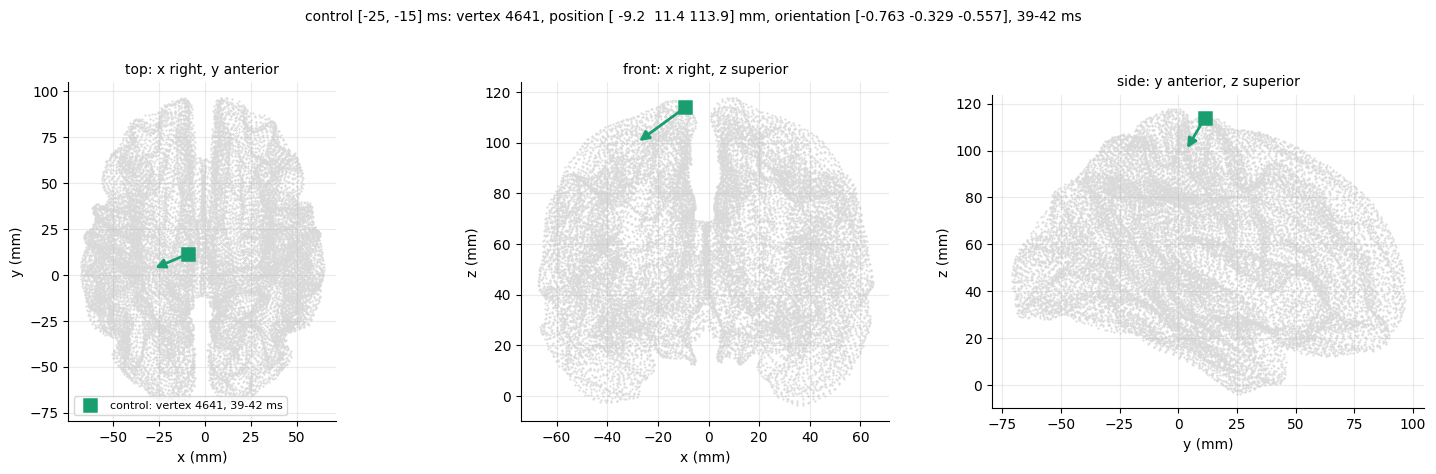

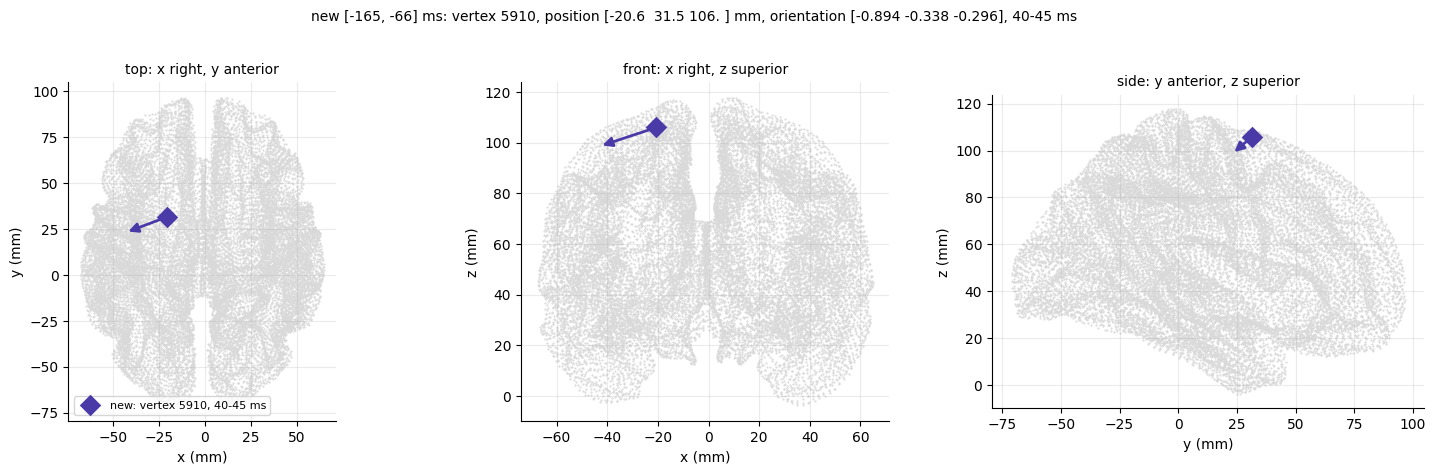

In [38]:
SOURCE_RR = ONLINE["fitter"]._forward["source_rr"] * 1e3            # mm
VIEWS = [(0, 1, "top: x right, y anterior"), (0, 2, "front: x right, z superior"), (1, 2, "side: y anterior, z superior")]


def draw_dipoles(axes, names, arrow_mm=25):
    for ax, (h, v, title) in zip(axes, VIEWS):
        ax.scatter(SOURCE_RR[:, h], SOURCE_RR[:, v], s=0.3, color="0.85", rasterized=True)
        for name in names:
            d, st = DIPOLES[name], SOURCE_STYLE[name]
            p, o = d["position_mm"], d["orientation"] * arrow_mm
            ring = name == "online" and len(names) > 1        # online on top: a ring and a thin arrow
            ax.annotate("", xy=(p[h] + o[h], p[v] + o[v]), xytext=(p[h], p[v]),
                        arrowprops=dict(arrowstyle="-|>", color=st["color"], lw=0.9 if ring else 2,
                                        mutation_scale=9 if ring else 14))
            ax.plot(p[h], p[v], st["marker"], color=st["color"], mfc="none" if ring else st["mfc"],
                    ms=16 if ring else 9, mew=1.8,
                    label=f"{name}: vertex {d['vertex']}, {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms")
        ax.set_xlabel(f"{'xyz'[h]} (mm)")
        ax.set_ylabel(f"{'xyz'[v]} (mm)")
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")


for name in ARMS:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    draw_dipoles(axes, [name])
    axes[0].legend(fontsize=8, loc="lower left")
    d = DIPOLES[name]
    fig.suptitle(f"{ARMS[name]['label']}: vertex {d['vertex']}, position {np.round(d['position_mm'], 1)} mm, "
                 f"orientation {np.round(d['orientation'], 3)}, {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms",
                 y=1.02, fontsize=10)
    fig.tight_layout()
    plt.show()

### 3.5 Save

Written to each arm's folder: the files `run_calibration()` writes online (`calibration_bundle.npy`,
`dipole_fitting_info.npy`, `proc_info.npy`, `calibration_summary.csv`, `classifier_after_calibration.pt`) and
what it does not save: `tep_normalizer.npy` (calibration mean and SD, calibration amplitudes and labels),
`calibration_outcomes.csv`, `calibration_log.txt` and `replay_config.json` (parameters, prime commit, package
versions). The folders are rewritten on every run.

In [39]:
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
            "pandas": pd.__version__, "mne": mne.__version__, "mne_icalabel": mne_icalabel.__version__,
            "torch": torch.__version__}
for name, arm in ARMS.items():
    cal, out = CALIB[name], arm["dir"]
    np.save(out / "calibration_bundle.npy", cal["bundle"], allow_pickle=True)
    np.save(out / "dipole_fitting_info.npy", cal["fitting_info"], allow_pickle=True)
    np.save(out / "proc_info.npy", {
        "ch_names": list(cal["pp"]._info_processed["ch_names"]), "sfreq": PROC_SFREQ,
        "pre": {"tmin": QC_TMIN, "tmax": QC_TMAX}, "post": {"tmin": POST_TMIN, "tmax": POST_TMAX},
        "dipole": {"tmin": DIP_TMIN, "tmax": DIP_TMAX}, "proc_shape": ("n_channels", "n_times"),
        "units": "as received from the acquisition stream (microvolt-scale, uncalibrated)",
        "baseline": list(arm["baseline"]), "post_initial": [arm["post_initial_tmin"], POST_I_TMAX],
    }, allow_pickle=True)
    pd.DataFrame({"num_calibration_trials": [len(cal["kept"])]}).to_csv(out / "calibration_summary.csv", index=False)
    cal["predictor"].save_checkpoint(out / "classifier_after_calibration.pt")
    nz = cal["normalizer"]
    np.save(out / "tep_normalizer.npy", {
        "cal_mean": nz._cal_mean, "cal_std": nz._cal_std, "ewma_span": nz.ewma_span,
        "warmup_period": nz.warmup_period, "scale_factor": nz.scale_factor, "calibration_trials": cal["kept"],
        "calibration_amplitudes": cal["amplitudes"], "calibration_labels": cal["labels"],
    }, allow_pickle=True)
    OUTCOMES[["online", name]].to_csv(out / "calibration_outcomes.csv")
    (out / "calibration_log.txt").write_text(cal["log"], encoding="utf-8")
    (out / "replay_config.json").write_text(json.dumps({
        "subject": SUBJECT_ID, "session": SESSION_ID, "run": RUN_ID, "arm": name,
        "baseline_s": list(arm["baseline"]), "post_initial_tmin_s": arm["post_initial_tmin"],
        "raw_window_s": list(RAW_WINDOW), "online_dir": str(ONLINE_DIR), "new_raw_dir": str(NEW_RAW_DIR),
        "session_overrides": OVERRIDES, "seed": SEED, "prime_commit": PRIME_COMMIT, "device": DEVICE_NOTE,
        "versions": VERSIONS, "created": datetime.now().isoformat(timespec="seconds"),
    }, indent=2))
    print(f"{arm['label']:28s} -> {out}")

control [-25, -15] ms        -> D:\Linus\Loop\offline_baseline\sub-pilot005\control_baseline_-25_-15ms
new [-165, -66] ms           -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_-165_-66ms


## 4 · Continual adaptation

### 4.1 Check: do the replayed windows reproduce the online predictions?

Online, a non-forced PRIME trial was predicted on the 200 ms window that triggered it. That window ends at
`trigger_time`, and the pulse follows about `TRIGGER_OFFSET` = 10 ms later. When the latency is exactly 10.0 ms,
the pulse-aligned `_pre_raw` [−210, −10] ms is that window. At other latencies the window is shifted by one or
more samples, and when it starts before −210 ms no raw file holds it. `_pre_proc.npy`, captured right before the
MAD gates, holds it for every PRIME trial. Forced and predetermined trials were predicted on `_pre_raw`
itself.

The check loads each trial's online checkpoint (`classifier_after_trial_<g>.pt`, the model state when that
prediction was made) and predicts on the replayed window, from `_pre_proc` and from `_pre_raw`. The window that
was used online should reproduce the logged `prediction_probability` to float precision.

In [40]:
def gate_pre(pp, pre_epoch):
    # The end of Preprocessor.preprocess_pre(): global MAD gate, local MAD gate, crop to the model window.
    # _pre_proc.npy was captured right before these gates, so this finishes preprocess_pre() on it.
    stats_qc = pp.calibration_params["good_trial_stats_qc"]
    opts = pp._opts["trial_reject_opts"]["pre"]
    if global_mad_zscore_rejected(pre_epoch, stats_qc["mads_mean"], stats_qc["mads_std"],
                                  opts["global_zscore_threshold"], pp._mad_workspace):
        return None, "global_mad"
    if local_mad_zscore_rejected(pre_epoch, opts["local_zscore_threshold"], pp._mad_workspace):
        return None, "local_mad"
    return model_crop(pre_epoch), None


def pre_from_raw(pp, stem):
    # preprocess_pre_from_pulse(): the pulse-aligned window, with the reason when a gate rejects it.
    pre, epoch = run_preprocess_pre(pp, stem)
    return pre, (None if pre is not None else gate_pre(pp, epoch)[1]), epoch


rows = []
for r in SINGLES[SINGLES.prediction_probability.notna()].itertuples():
    ck = ONLINE_DIR / ("classifier_after_calibration.pt" if r.g == 0 else f"classifier_after_trial_{r.g}.pt")
    if not ck.is_file():
        continue
    model = checkpoint_model(ck)
    pre, _, epoch = pre_from_raw(ONLINE["pp"], r.stem)
    row = dict(stem=r.stem, condition=r.condition, lat_ms=r.lat_ms, online=r.prediction_probability,
               from_pre_raw=model.predict(pre) if pre is not None else np.nan)
    proc_path = ONLINE_DIR / f"{r.stem}_pre_proc.npy"
    if r.condition == "prime_single_pulse" and proc_path.is_file():
        proc = np.load(proc_path)
        pre_p, _ = gate_pre(ONLINE["pp"], proc)
        row.update(from_pre_proc=model.predict(pre_p) if pre_p is not None else np.nan,
                   pre_raw_is_window=bool(np.array_equal(epoch, proc)))
    rows.append(row)
CHECK = pd.DataFrame(rows)

if CHECK.empty:
    print("no online per-trial checkpoints found: check skipped")
else:
    CHECK["used_online"] = np.where(CHECK.condition == "prime_single_pulse",
                                    CHECK.get("from_pre_proc", np.nan), CHECK.from_pre_raw)
    CHECK["|Δp| window used online"] = (CHECK.used_online - CHECK.online).abs()
    CHECK["|Δp| _pre_raw"] = (CHECK.from_pre_raw - CHECK.online).abs()
    CHECK["latency"] = np.where(CHECK.condition == "prime_single_pulse",
                                CHECK.lat_ms.map("{:.1f} ms".format), "pulse-aligned")
    summary = CHECK.groupby(["condition", "latency"]).agg(
        trials=("stem", "size"),
        pre_raw_is_the_window=("pre_raw_is_window", lambda v: str(int(v.astype(float).sum())) if v.notna().any() else "–"),
        max_dp_window_used_online=("|Δp| window used online", "max"),
        max_dp_pre_raw=("|Δp| _pre_raw", "max"))
    display(summary)
    print(f"window used online: max |Δp| = {CHECK['|Δp| window used online'].max():.1e} over {len(CHECK)} trials")

trials pre_raw_is_the_window  max_dp_window_used_online  max_dp_pre_raw
condition            latency                                                                               
predetermined_single pulse-aligned      74                     –                   0.000034        0.000034
prime_single_pulse   10.0 ms           195                     0                   0.000045        0.000045
                     10.2 ms            26                     0                   0.000023        0.007741
                     11.0 ms             2                     0                   0.000004        0.019857
                     11.2 ms             5                     0                   0.000019        0.034023
                     9.8 ms              3                     0                   0.000013        0.003188

window used online: max |Δp| = 4.5e-05 over 305 trials


### 4.2 Replay

Trial by trial, in session order, as `process_intervention_pulse()` and `analyze_tep()` in `2_intervention.py`:

1. **TEP**: `preprocess_post()` on the arm's raw buffer → `fit_trial()` (free orientation) with the arm's
   dipole → `TEPNormalizer.transform_verbose()`, which also appends the amplitude to the normaliser's EWMA history.
   Rejected trials get no amplitude and do not enter the history.
2. **Prediction window**: every single pulse (`prime_single_pulse`, forced or not, and `predetermined_single`) →
   the pulse-aligned `_pre_raw` [−210, −10] ms through the arm's own `preprocess_pre()` (interpolation, filter,
   average reference, MAD gates, crop to the model window). No online-preprocessed file (`_pre_proc.npy`) is used.
   For non-forced PRIME trials this is not exactly the window that triggered the pulse (they differ when the
   trigger-to-pulse latency is not 10.0 ms, see 4.1), so the control arm's predictions deviate slightly from the
   online log.
3. **Prediction**: made before the trial's finetuning step, as online. Unlike online, every single pulse whose
   window passes the gates gets one, including forced trials and predetermined trials with a rejected post window.
4. **Finetuning**: `finetune(window, label)` when both exist. The prediction value does not enter the update.

`prime_triplet` trials are skipped: online they neither update the normaliser nor finetune the model. The model is
saved at the end of each block under the online names (`classifier_after_trial_200.pt`, …), so code that loads the
online checkpoints can load these.

In [41]:
ONLINE_COLS = ["prediction_probability", "preprocessing_failed", "postprocessing_failed", "post_reject_reason",
               "tep_amplitude", "tep_amplitude_raw"]


def pre_window(pp, r):
    # Prediction and finetuning window of every trial: the pulse-aligned _pre_raw [-210, -10] ms through the arm's
    # own preprocess_pre(). No online-preprocessed file (_pre_proc.npy) is used.
    pre, reason, _ = pre_from_raw(pp, r.stem)
    return pre, reason, "_pre_raw"


def replay_intervention(name):
    arm, cal = ARMS[name], CALIB[name]
    pp, fitter, normalizer, predictor = cal["pp"], cal["fitter"], cal["normalizer"], cal["predictor"]
    set_rng_state(cal["rng"])                  # continue the random stream of this arm's calibration
    rows, t0 = [], time.time()
    for block in BLOCKS:
        for r in IV[IV.stage == block].itertuples():
            row = dict(stem=r.stem, replayed=r.condition != "prime_triplet")
            if row["replayed"]:
                # analyze_tep(): preprocess_post -> fit_trial -> transform_verbose (appends to the EWMA history)
                x, t = post_buffer(r.stem, arm["post_initial_tmin"])
                post = pp.preprocess_post(x, t)
                row.update(postprocessing_failed=post is None, post_reject_reason=pp.last_post_reject_reason)
                if post is not None:
                    tep = normalizer.transform_verbose(fitter.fit_trial(post))
                    row.update(tep_amplitude=tep["label"], tep_amplitude_raw=tep["raw"], tep_ewma=tep["ewma"],
                               tep_detrended=tep["detrended"], tep_zscore=tep["zscore"])
                # prediction on the trial's window, before its finetuning step
                pre, reason, source = pre_window(pp, r)
                row.update(pre_source=source, preprocessing_failed=pre is None, pre_reject_reason=reason,
                           prediction_probability=predictor.predict(pre) if pre is not None else np.nan)
                # process_intervention_pulse(): finetune on (window, label) of single pulses
                row["finetuned"] = bool(pre is not None and post is not None)
                if row["finetuned"]:
                    predictor.finetune(pre, row["tep_amplitude"])
            rows.append(row)
        predictor.save_checkpoint(arm["dir"] / f"classifier_after_trial_{BLOCK_END[block]}.pt")
    rep = pd.DataFrame(rows)
    online = IV[["stem", "stage", "trial_in_stage", "condition", "is_forced", "g", "lat_ms"] + ONLINE_COLS]
    rep = online.rename(columns={c: "online_" + c for c in ONLINE_COLS}).merge(rep, on="stem", how="left")
    n = int(rep.replayed.sum())
    print(f"{arm['label']}: {n} single pulses in {time.time() - t0:.0f} s; prediction windows from _pre_raw")
    return rep


REP = {name: replay_intervention(name) for name in ARMS}

control [-25, -15] ms: 320 single pulses in 32 s; prediction windows from _pre_raw
new [-165, -66] ms: 320 single pulses in 30 s; prediction windows from _pre_raw


### 4.3 Replay against the online log

For the control arm every value should match the online log: rejections exactly, TEP amplitudes and labels to
float precision. Its predictions come from a model that was calibrated and finetuned again, so GPU arithmetic
can make them drift slightly. The size of that drift is the noise floor for comparing the new arm with the
online log. Both arms are summarised per condition.

In [42]:
def replay_counts(rep):
    s = rep[rep.replayed.fillna(False).astype(bool)]
    return pd.DataFrame({
        "trials": s.groupby("condition").size(),
        "post rejected": s.groupby("condition").postprocessing_failed.sum(),
        "post rejected online": s.groupby("condition").online_postprocessing_failed.sum(),
        "pre rejected": s.groupby("condition").preprocessing_failed.sum(),
        "predicted": s.groupby("condition").prediction_probability.count(),
        "predicted online": s.groupby("condition").online_prediction_probability.count(),
        "finetuned": s.groupby("condition").finetuned.sum(),
    }).astype(int)


for name, rep in REP.items():
    print(f"── {ARMS[name]['label']}")
    display(replay_counts(rep))

if "control" in REP:
    s = REP["control"][REP["control"].replayed.fillna(False).astype(bool)]
    fail, fail_on = s.postprocessing_failed.astype(bool), s.online_postprocessing_failed.astype(bool)
    reason, reason_on = s.post_reject_reason.fillna("kept"), s.online_post_reject_reason.fillna("kept")
    both = s[~fail & ~fail_on]
    raw_rel = (both.tep_amplitude_raw / both.online_tep_amplitude_raw - 1).abs()
    lab = (both.tep_amplitude - both.online_tep_amplitude).abs()
    pr = s.dropna(subset=["prediction_probability", "online_prediction_probability"])
    dp = (pr.prediction_probability - pr.online_prediction_probability).abs()
    print("control arm vs online log")
    print(f"  postprocessing_failed identical : {int((fail == fail_on).sum())} / {len(s)}")
    print(f"  post_reject_reason identical    : {int((reason == reason_on).sum())} / {len(s)}")
    print(f"  tep_amplitude_raw               : max relative difference {raw_rel.max():.1e} ({len(both)} trials)")
    print(f"  tep_amplitude (label)           : max |diff| {lab.max():.1e}")
    if len(pr):
        first = pr[dp > 0.01].stem.iloc[0] if (dp > 0.01).any() else "none"
        print(f"  prediction_probability          : r = {stats.pearsonr(pr.prediction_probability, pr.online_prediction_probability)[0]:.4f}, "
              f"median |Δp| {dp.median():.1e}, max |Δp| {dp.max():.1e} ({len(pr)} trials); first |Δp| > 0.01: {first}")

── control [-25, -15] ms


,trials,post rejected,post rejected online,pre rejected,predicted,predicted online,finetuned
condition,,,,,,,
predetermined_single,80,6,6,0,80,74,74
prime_single_pulse,240,19,19,0,240,231,221


── new [-165, -66] ms


,trials,post rejected,post rejected online,pre rejected,predicted,predicted online,finetuned
condition,,,,,,,
predetermined_single,80,17,6,0,80,74,63
prime_single_pulse,240,49,19,0,240,231,191


control arm vs online log
  postprocessing_failed identical : 320 / 320
  post_reject_reason identical    : 320 / 320
  tep_amplitude_raw               : max relative difference 3.5e-05 (295 trials)
  tep_amplitude (label)           : max |diff| 1.1e-16
  prediction_probability          : r = 0.9997, median |Δp| 7.6e-04, max |Δp| 3.4e-02 (305 trials); first |Δp| > 0.01: intervention_block_1_0050


### 4.4 Trial table

One `trials_intervention.csv` per arm, with the rows of the online file (calibration and intervention) and:

- the replayed values under the online column names (`prediction_probability`, `tep_amplitude`,
  `postprocessing_failed`, …), plus `pre_source`, `pre_reject_reason`, `finetuned` and `replayed`;
- the online values with an `online_` prefix;
- the online timing columns, unchanged, and `trigger_latency_ms`.

Calibration rows carry the calibration amplitude and label of surviving trials, and the gate that dropped a trial
in `calibration_dropped` / `online_calibration_dropped`. Triplet rows have `replayed = False` and no replayed
values.

In [43]:
TIMING = ["iti", "trial_start_time", "target_time", "max_time", "trigger_time", "pulse_time", "prime_attempts",
          "qc_failures", "threshold", "search_time"]
REPLAYED_COLS = ["replayed", "preprocessing_failed", "pre_reject_reason", "pre_source", "postprocessing_failed",
                 "post_reject_reason", "prediction_probability", "tep_amplitude", "tep_amplitude_raw", "tep_ewma",
                 "tep_detrended", "tep_zscore", "finetuned", "calibration_dropped"]


def trial_table(name):
    cal = CALIB[name]
    gate_of = lambda bundle: {int(i): GATE_NAMES[g] for g, idx in bundle["trials_dropped"].items() for i in idx}
    dropped, dropped_on = gate_of(cal["bundle"]), gate_of(ONLINE["bundle"])
    amp, lab = dict(zip(cal["kept"], cal["amplitudes"])), dict(zip(cal["kept"], cal["labels"]))
    cal_rows = pd.DataFrame([dict(
        stem=r.stem, replayed=True,
        calibration_dropped=dropped.get(r.trial_in_stage, ""),
        online_calibration_dropped=dropped_on.get(r.trial_in_stage, ""),
        preprocessing_failed=dropped.get(r.trial_in_stage) == GATE_NAMES["qc"],
        postprocessing_failed=dropped.get(r.trial_in_stage) in (GATE_NAMES["ocular"], GATE_NAMES["post"]),
        tep_amplitude_raw=amp.get(r.trial_in_stage, np.nan), tep_amplitude=lab.get(r.trial_in_stage, np.nan),
    ) for r in CAL.itertuples()])
    iv_rows = REP[name].drop(columns=["stage", "trial_in_stage", "condition", "is_forced", "g", "lat_ms"]
                             + ["online_" + c for c in ONLINE_COLS])
    table = TRIALS[["stem", "stage", "trial_in_stage", "condition", "is_forced", "trial_order", "lat_ms"] + TIMING]
    table = table.merge(pd.concat([cal_rows, iv_rows], ignore_index=True), on="stem", how="left")
    for c in ONLINE_COLS:
        table["online_" + c] = TRIALS[c].to_numpy()
    table = table.rename(columns={"lat_ms": "trigger_latency_ms"})
    columns = (["stage", "trial_in_stage", "condition", "is_forced", "trial_order"] + REPLAYED_COLS
               + ["online_" + c for c in ONLINE_COLS] + ["online_calibration_dropped"] + TIMING + ["trigger_latency_ms"])
    return table[columns]


TABLES = {}
for name, arm in ARMS.items():
    TABLES[name] = trial_table(name)
    TABLES[name].to_csv(arm["dir"] / "trials_intervention.csv", index=False)
    print(f"{arm['label']:28s} -> {arm['dir'] / 'trials_intervention.csv'} ({len(TABLES[name])} rows)")
display(TABLES["new"][TABLES["new"].condition == "prime_single_pulse"].head(5))

control [-25, -15] ms        -> D:\Linus\Loop\offline_baseline\sub-pilot005\control_baseline_-25_-15ms\trials_intervention.csv (925 rows)
new [-165, -66] ms           -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_-165_-66ms\trials_intervention.csv (925 rows)


,stage,trial_in_stage,condition,is_forced,trial_order,replayed,preprocessing_failed,pre_reject_reason,pre_source,postprocessing_failed,post_reject_reason,prediction_probability,tep_amplitude,tep_amplitude_raw,tep_ewma,tep_detrended,tep_zscore,finetuned,calibration_dropped,online_prediction_probability,online_preprocessing_failed,online_postprocessing_failed,online_post_reject_reason,online_tep_amplitude,online_tep_amplitude_raw,online_calibration_dropped,iti,trial_start_time,target_time,max_time,trigger_time,pulse_time,prime_attempts,qc_failures,threshold,search_time,trigger_latency_ms
128,intervention_block_1,3,prime_single_pulse,False,128,True,False,NaN,_pre_raw,False,None,0.662887,0.154930,0.021402,0.030157,-0.008756,-0.906019,True,NaN,0.805458,False,False,NaN,0.487805,0.031802,NaN,NaN,464.9800,467.5300,470.4800,467.5200,467.5300,6.0,0.0,0.773000,0.0600,10.0
131,intervention_block_1,6,prime_single_pulse,False,131,True,False,NaN,_pre_raw,False,None,0.857121,0.028169,0.012634,0.028809,-0.016175,-1.614127,True,NaN,0.820352,False,False,NaN,0.536585,0.034844,NaN,NaN,473.3902,475.9102,478.8902,475.9002,475.9102,3.0,0.0,0.793196,0.0300,10.0
133,intervention_block_1,8,prime_single_pulse,False,133,True,False,NaN,_pre_raw,False,None,0.826970,0.492958,0.027018,0.028671,-0.001653,-0.228195,True,NaN,0.801886,False,False,NaN,0.012195,0.013568,NaN,NaN,479.4802,482.2102,484.9802,482.2002,482.2104,24.0,0.0,0.796996,0.2402,10.2
138,intervention_block_1,13,prime_single_pulse,False,138,True,False,NaN,_pre_raw,False,None,0.810049,0.859155,0.041844,0.029685,0.012159,1.089918,True,NaN,0.816413,False,True,ocular,NaN,NaN,NaN,NaN,494.5306,497.2906,500.0306,497.2806,497.2906,27.0,0.0,0.815988,0.2700,10.0
139,intervention_block_1,14,prime_single_pulse,False,139,True,False,NaN,_pre_raw,False,None,0.824652,0.746479,0.035036,0.030097,0.004940,0.400948,True,NaN,0.824840,False,False,NaN,0.719512,0.043360,NaN,NaN,497.2906,499.8706,502.7906,499.8606,499.8706,9.0,0.0,0.823588,0.0900,10.0


## 5 · Calibration compared with the online calibration

### 5.1 All outcomes

The table of 3.3 with the online column. `≠` marks an outcome that differs from online at the precision shown;
rows without an online value are left unmarked. For the control arm, every mark is replay noise.

In [44]:
COMPARISON = OUTCOMES[SOURCES].copy()
for name in ARMS:
    differs = (COMPARISON[name] != COMPARISON["online"]) & (COMPARISON["online"] != "–")
    COMPARISON[f"{name} ≠ online"] = np.where(differs, "≠", "")
display(COMPARISON)
COMPARISON.to_csv(ARMS["new"]["dir"] / "calibration_comparison.csv")
changed = COMPARISON.index[COMPARISON["new ≠ online"] == "≠"]
print(f"new baseline: {len(changed)} of {len(COMPARISON)} calibration outcomes differ from online")

online                                                control  \
group                   outcome                                                                                                                                                        
trials                  dropped: ocular                                                                                    13                                                     13   
                        dropped: pre-stimulus MAD                                                                           4                                                      4   
                        dropped: post-stimulus MAD                                                                          1                                                      1   
                        used for calibration                                                                              107                                                    107   
                        dropped by ocular: trial index                  0, 17, 20, 46, 53, 60, 67, 80, 90, 105, 110, 116, 118  0, 17, 20, 46, 53, 60, 67, 80, 90, 105, 110, 116, 118   
                        dropped by pre-stimulus MAD: trial index                                               15, 18, 23, 39                                         15, 18, 23, 39   
                        dropped by post-stimulus MAD: trial index                                                          76                                                     76   
bad channels            interpolated                                                                              C3, CP3, T8                                            C3, CP3, T8   
                        flagged pre-stimulus (MAD, power, autocorr.)                                                        –                                                     T8   
                        flagged post-stimulus (evoked AUC 20-60 ms)                                                         –                                                C3, CP3   
ICA                     method / components                                                                      infomax / 11                                           infomax / 11   
                        excluded components                                                                           0, 1, 2                                                0, 1, 2   
                        ICLabel of excluded                                 eye blink 0.984, eye blink 0.977, eye blink 0.999      eye blink 0.984, eye blink 0.977, eye blink 0.999   
                        unmixing matrix: max |Δ| to online                                                                  –                                                6.2e-11   
ocular gate             z threshold                                                                                       2.5                                                    2.5   
                        median |z| over (ms)                                                                        15 to 100                                              15 to 100   
                        mean / SD taken over (ms)                                                                  -30 to 100                                             -30 to 100   
                        IC 0: mean / SD of |source|                                                             0.500 / 0.784                                          0.500 / 0.784   
                        IC 1: mean / SD of |source|                                                             0.543 / 0.809                                          0.543 / 0.809   
                        IC 2: mean / SD of |source|                                                             0.322 / 0.646                                          0.322 / 0.646   
pre-stimulus MAD gate   mean / SD of trial MAD                         

new baseline: 30 of 49 calibration outcomes differ from online


### 5.2 Dipoles

Online and replayed dipoles in one plot, and how far apart they are: distance between the vertices, angle
between the orientations, and the shift of the fitted time window.

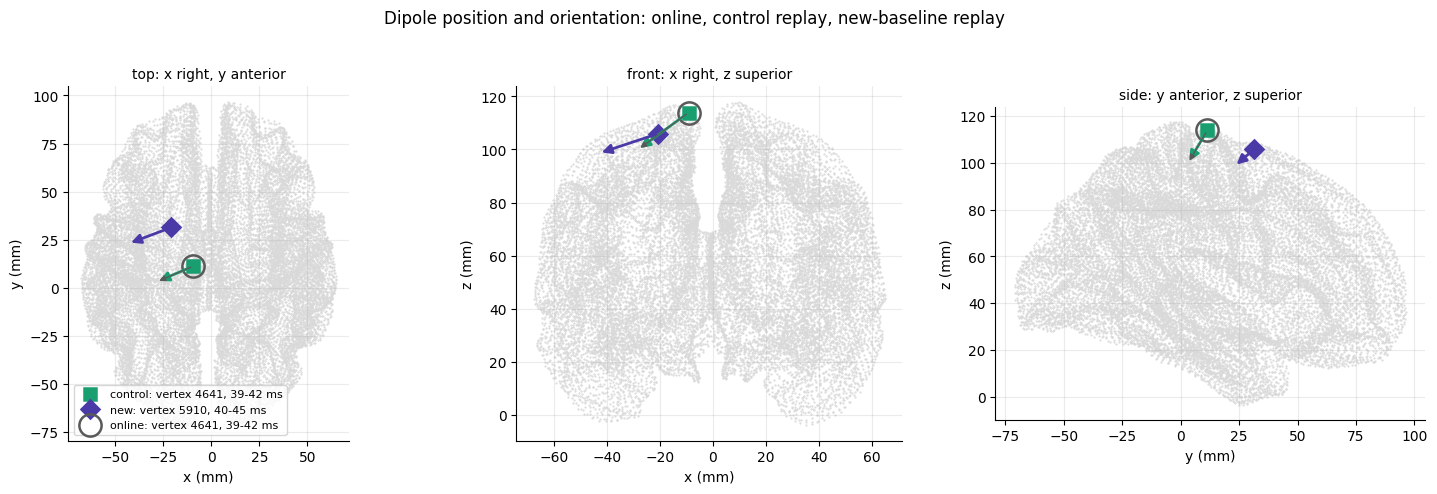

,vertices,distance (mm),orientation angle (°),windows (ms),window start shift (ms),shared samples
comparison,,,,,,
control vs online,4641 vs 4641,0.0,0.0,39-42 vs 39-42,0.0,4
new vs online,5910 vs 4641,24.4,16.8,40-45 vs 39-42,1.0,3
new vs control,5910 vs 4641,24.4,16.8,40-45 vs 39-42,1.0,3


In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
draw_dipoles(axes, list(ARMS) + ["online"])
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Dipole position and orientation: online, control replay, new-baseline replay", y=1.02)
fig.tight_layout()
plt.show()


def angle_deg(a, b):
    return float(np.degrees(np.arccos(np.clip(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)), -1, 1))))


pairs = [(name, "online") for name in ARMS] + ([("new", "control")] if "control" in ARMS else [])
rows = []
for a, b in pairs:
    da, db = DIPOLES[a], DIPOLES[b]
    (sa, ea), (sb, eb) = da["index_range"], db["index_range"]
    rows.append({"comparison": f"{a} vs {b}", "vertices": f"{da['vertex']} vs {db['vertex']}",
                 "distance (mm)": round(float(np.linalg.norm(da["position_mm"] - db["position_mm"])), 1),
                 "orientation angle (°)": round(angle_deg(da["orientation"], db["orientation"]), 1),
                 "windows (ms)": f"{da['window_ms'][0]:.0f}-{da['window_ms'][1]:.0f} vs "
                                 f"{db['window_ms'][0]:.0f}-{db['window_ms'][1]:.0f}",
                 "window start shift (ms)": da["window_ms"][0] - db["window_ms"][0],
                 "shared samples": max(0, min(ea, eb) - max(sa, sb))})
DIPOLE_DIFF = pd.DataFrame(rows).set_index("comparison")
display(DIPOLE_DIFF)

### 5.3 ICA components

ICLabel label and probability of every component, for the online ICA and each arm's ICA. The excluded
(ocular) components are marked. If the bad channels did not change, the ICA is the same and so are the labels.

In [46]:
ica_table = pd.concat({src: ICA_LABELS[src].assign(
    excluded=lambda d, s=src: np.where(np.isin(d.index, CAL_SRC[s]["bundle"]["ica"].exclude), "×", ""))
    for src in SOURCES}, axis=1)
ica_table.index.name = "component"
display(ica_table.round(3))

online                         control                             new                     
               label probability excluded      label probability excluded      label probability excluded
component                                                                                                
0          eye blink       0.984        ×  eye blink       0.984        ×  eye blink       0.984        ×
1          eye blink       0.977        ×  eye blink       0.977        ×  eye blink       0.977        ×
2          eye blink       0.999        ×  eye blink       0.999        ×  eye blink       0.999        ×
3              brain       0.999               brain       0.999               brain       0.999         
4              brain       0.996               brain       0.996               brain       0.996         
5              brain       0.998               brain       0.998               brain       0.998         
6              brain       1.000               brain       1.000               brain       1.000         
7              brain       1.000               brain       1.000               brain       1.000         
8              brain       0.993               brain       0.993               brain       0.993         
9              brain       0.915               brain       0.915               brain       0.915         
10             brain       0.998               brain       0.998               brain       0.998

### 5.4 Gate statistics

The per-trial MAD values that set the pre- and post-stimulus MAD gates (`good_trial_stats_qc` / `_post`, computed
on the calibration trials that survived the earlier gates).

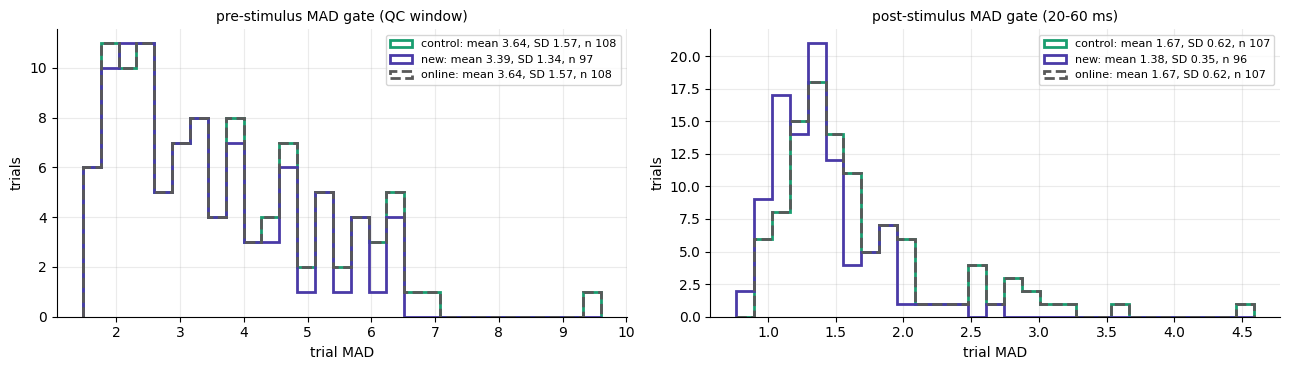

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, key, title in zip(axes, ("good_trial_stats_qc", "good_trial_stats_post"),
                          ("pre-stimulus MAD gate (QC window)", "post-stimulus MAD gate (20-60 ms)")):
    values = {src: np.asarray(CAL_SRC[src]["bundle"][key]["mads"]) for src in DRAW_ORDER}
    bins = np.linspace(min(v.min() for v in values.values()), max(v.max() for v in values.values()), 30)
    for src, v in values.items():
        st = SOURCE_STYLE[src]
        ax.hist(v, bins=bins, histtype="step", lw=2, color=st["color"], ls=st["ls"],
                label=f"{src}: mean {v.mean():.2f}, SD {v.std():.2f}, n {len(v)}")
    ax.set_xlabel("trial MAD")
    ax.set_ylabel("trials")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 5.5 Calibration TEP, SSP-SIR kernel, calibration amplitudes

Left: global field power of the calibration evoked response ([1, 100] ms, surviving trials), with each source's
dipole window shaded. Middle: the SSP-SIR artifact kernel (how strongly each time point is corrected). Right:
the dipole amplitudes of the calibration trials, which the normaliser is fitted to.

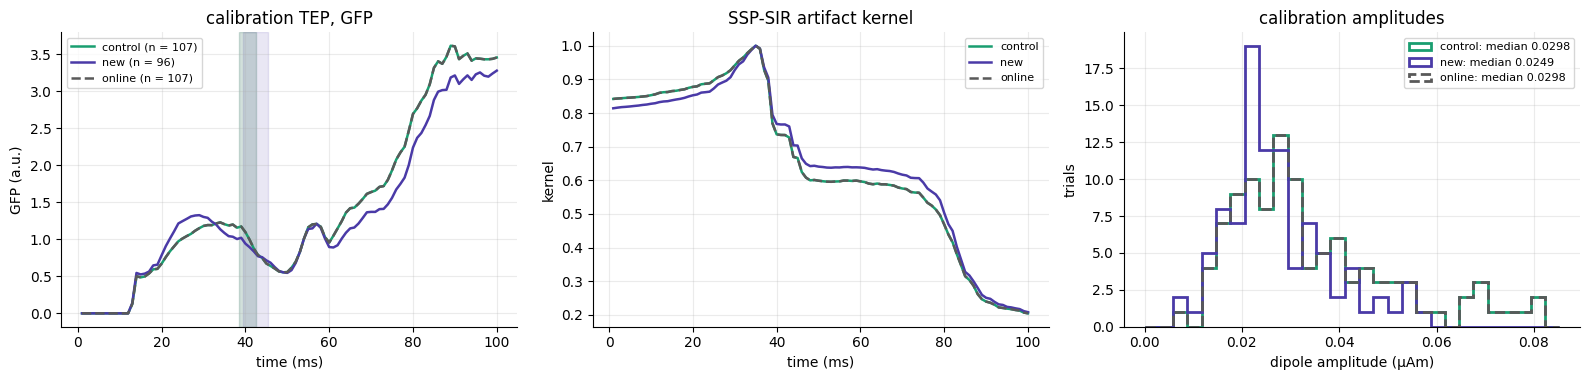

In [48]:
times_ms = (POST_TMIN + np.arange(ONLINE["cal_epochs"].shape[2]) / PROC_SFREQ) * 1e3
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
for src in DRAW_ORDER:
    st, s = SOURCE_STYLE[src], CAL_SRC[src]
    gfp = s["cal_epochs"].mean(axis=0).std(axis=0)
    axes[0].plot(times_ms, gfp, color=st["color"], ls=st["ls"], lw=1.8, label=f"{src} (n = {len(s['cal_epochs'])})")
    w = DIPOLES[src]["window_ms"]
    axes[0].axvspan(w[0] - 0.5, w[1] + 0.5, color=st["color"], alpha=0.12)
    axes[1].plot(times_ms, s["bundle"]["sspsir_filter_kernel"][0], color=st["color"], ls=st["ls"], lw=1.8, label=src)
    a = s["amplitudes"]
    axes[2].hist(a, bins=np.linspace(0, np.percentile(np.concatenate([CAL_SRC[x]["amplitudes"] for x in SOURCES]), 99), 30),
                 histtype="step", lw=2, color=st["color"], ls=st["ls"], label=f"{src}: median {np.median(a):.4f}")
axes[0].set(xlabel="time (ms)", ylabel="GFP (a.u.)", title="calibration TEP, GFP")
axes[1].set(xlabel="time (ms)", ylabel="kernel", title="SSP-SIR artifact kernel")
axes[2].set(xlabel="dipole amplitude (µAm)", ylabel="trials", title="calibration amplitudes")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6 · Rejections compared with the online rejections

### 6.1 Calibration

Trials dropped per gate, in the order the gates run (ocular → pre-stimulus MAD → post-stimulus MAD), and how
many of them the online calibration dropped too.

In [49]:
rows = []
sets_online = {label: set(int(i) for i in ONLINE["bundle"]["trials_dropped"][gate]) for gate, label in GATE_NAMES.items()}
sets_online["kept"] = set(ONLINE["kept"])
for label, on in sets_online.items():
    row = {"gate": label, "online": len(on)}
    for name in ARMS:
        b = CALIB[name]["bundle"]
        ar = set(CALIB[name]["kept"]) if label == "kept" else set(
            int(i) for i in b["trials_dropped"][next(g for g, l in GATE_NAMES.items() if l == label)])
        row.update({name: len(ar), f"{name}: also online": len(ar & on), f"{name}: only {name}": len(ar - on),
                    f"{name}: only online": len(on - ar)})
    rows.append(row)
CAL_REJECTIONS = pd.DataFrame(rows).set_index("gate")
display(CAL_REJECTIONS)

,online,control,control: also online,control: only control,control: only online,new,new: also online,new: only new,new: only online
gate,,,,,,,,,
ocular,13,13,13,0,0,25,10,15,3
pre-stimulus MAD,4,4,4,0,0,3,3,0,1
post-stimulus MAD,1,1,1,0,0,1,0,1,1
kept,107,107,107,0,0,96,92,4,15


### 6.2 Intervention single pulses

`postprocessing_failed` of the 320 single-pulse trials: online against each arm, by reason, by condition and by
block, and the trials that switched. Pre-stimulus gate failures are listed separately; online logged them only
for forced and predetermined trials.

In [50]:
REJ_ROWS = []
for name, rep in REP.items():
    s = rep[rep.replayed.fillna(False).astype(bool)].copy()
    s["online"] = s.online_post_reject_reason.fillna("kept")
    s["replay"] = s.post_reject_reason.fillna("kept")
    print(f"── {ARMS[name]['label']}: post-stimulus rejection, online (rows) vs replay (columns)")
    display(pd.crosstab(s.online, s.replay, margins=True))
    rej, rej_on = s.postprocessing_failed.astype(bool), s.online_postprocessing_failed.astype(bool)
    flags = s.assign(rejected_online=rej_on, rejected_replay=rej, both=rej & rej_on,
                     only_online=~rej & rej_on, only_replay=rej & ~rej_on)
    cols = ["rejected_online", "rejected_replay", "both", "only_online", "only_replay"]
    by = [flags.groupby(key)[cols].sum().assign(trials=flags.groupby(key).size())[["trials"] + cols]
          for key in ("condition", "stage")]
    display(pd.concat(by, keys=["condition", "block"]).astype(int))
    only_on, only_rep = s[~rej & rej_on], s[rej & ~rej_on]
    print(f"rejected online only ({len(only_on)}): {', '.join(only_on.stem.head(40))}")
    print(f"rejected in the replay only ({len(only_rep)}): {', '.join(only_rep.stem.head(40))}")
    pre = s.assign(pre_reject_reason=s.pre_reject_reason.fillna("passed"))
    print("pre-stimulus gates of the replayed prediction windows:")
    display(pd.crosstab(pre.condition, pre.pre_reject_reason, margins=True))
    REJ_ROWS.append({"arm": name, "single pulses": len(s), "post rejected online": int(rej_on.sum()),
                     "post rejected replay": int(rej.sum()), "only online": len(only_on),
                     "only replay": len(only_rep), "pre rejected replay": int(s.preprocessing_failed.astype(bool).sum())})
REJECTIONS = pd.DataFrame(REJ_ROWS).set_index("arm")

── control [-25, -15] ms: post-stimulus rejection, online (rows) vs replay (columns)


replay,global_mad,kept,local_mad,ocular,All
online,,,,,
global_mad,1,0,0,0,1
kept,0,295,0,0,295
local_mad,0,0,2,0,2
ocular,0,0,0,22,22
All,1,295,2,22,320


trials  rejected_online  rejected_replay  both  only_online  only_replay
condition predetermined_single      80                6                6     6            0            0
          prime_single_pulse       240               19               19    19            0            0
block     intervention_block_1      80               10               10    10            0            0
          intervention_block_2      80                6                6     6            0            0
          intervention_block_3      80                7                7     7            0            0
          intervention_block_4      80                2                2     2            0            0

rejected online only (0): 
rejected in the replay only (0): 
pre-stimulus gates of the replayed prediction windows:


pre_reject_reason,passed,All
condition,,
predetermined_single,80,80
prime_single_pulse,240,240
All,320,320


── new [-165, -66] ms: post-stimulus rejection, online (rows) vs replay (columns)


replay,global_mad,kept,local_mad,ocular,All
online,,,,,
global_mad,0,1,0,0,1
kept,3,249,2,41,295
local_mad,0,1,1,0,2
ocular,0,3,0,19,22
All,3,254,3,60,320


trials  rejected_online  rejected_replay  both  only_online  only_replay
condition predetermined_single      80                6               17     4            2           13
          prime_single_pulse       240               19               49    16            3           33
block     intervention_block_1      80               10               16     7            3            9
          intervention_block_2      80                6               14     4            2           10
          intervention_block_3      80                7               26     7            0           19
          intervention_block_4      80                2               10     2            0            8

rejected online only (5): intervention_block_1_0000, intervention_block_1_0013, intervention_block_1_0045, intervention_block_2_0131, intervention_block_2_0142
rejected in the replay only (46): intervention_block_1_0026, intervention_block_1_0060, intervention_block_1_0105, intervention_block_1_0118, intervention_block_1_0126, intervention_block_1_0158, intervention_block_1_0173, intervention_block_1_0185, intervention_block_1_0197, intervention_block_2_0007, intervention_block_2_0074, intervention_block_2_0083, intervention_block_2_0104, intervention_block_2_0108, intervention_block_2_0115, intervention_block_2_0117, intervention_block_2_0135, intervention_block_2_0149, intervention_block_2_0168, intervention_block_3_0001, intervention_block_3_0002, intervention_block_3_0004, intervention_block_3_0009, intervention_block_3_0014, intervention_block_3_0018, intervention_block_3_0023, intervention_block_3_0042, intervention_block_3_0047, intervention_block_3_0059, intervention_block_3_00

pre_reject_reason,passed,All
condition,,
predetermined_single,80,80
prime_single_pulse,240,240
All,320,320


## 7 · Prediction performance

Section 6 of `early_baseline_check.ipynb` for three sources side by side: the online log, the control replay and
the new-baseline replay. Each source uses its own predictions, labels and rejections, so n differs between
panels; the online log has no prediction for forced trials, the replays do. `tep_amplitude` is the normalised
label (EWMA-detrended, z-scored against calibration, mapped through the calibration ECDF); `tep_amplitude_raw` is
the free-orientation dipole amplitude at each source's own dipole, so raw amplitudes are not on a common scale
across sources. The PRIME trials were selected by the online model, so their predictions are range-restricted
for the online source; `predetermined_single` trials are the unselected ones.

### 7.0 Replayed vs online predictions on the same windows

How far the replayed model's predictions are from the online model's, trial by trial. For the control arm this is
the drift from recomputing calibration and finetuning; for the new arm it is what the new labels changed.

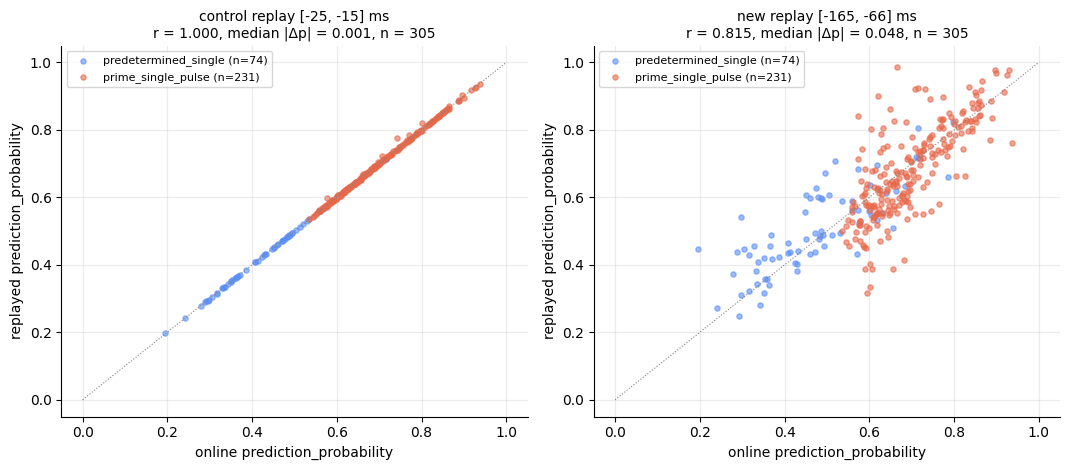

In [51]:
def source_label(src):
    return "online log" if src == "online" else f"{src} replay {ms(ARMS[src]['baseline'])}"


PERF = {"online": SINGLES.assign(p=SINGLES.prediction_probability, label=SINGLES.tep_amplitude,
                                 raw=SINGLES.tep_amplitude_raw)}
for name, rep in REP.items():
    s = rep[rep.replayed.fillna(False).astype(bool)]
    PERF[name] = s.assign(p=s.prediction_probability, label=s.tep_amplitude, raw=s.tep_amplitude_raw)
PERF = {src: d[["stem", "stage", "condition", "is_forced", "g", "p", "label", "raw"]].reset_index(drop=True)
        for src, d in PERF.items()}

fig, axes = plt.subplots(1, len(ARMS), figsize=(5.4 * len(ARMS), 4.8), squeeze=False)
for ax, name in zip(axes[0], ARMS):
    d = REP[name].dropna(subset=["prediction_probability", "online_prediction_probability"])
    for cond, color in CONDITION_COLORS.items():
        dc = d[d.condition == cond]
        ax.scatter(dc.online_prediction_probability, dc.prediction_probability, s=14, alpha=0.6, color=color,
                   label=f"{cond} (n={len(dc)})")
    ax.plot([0, 1], [0, 1], color="0.5", lw=0.8, ls=":")
    if len(d) >= 3:
        r = stats.pearsonr(d.online_prediction_probability, d.prediction_probability)[0]
        dp = (d.prediction_probability - d.online_prediction_probability).abs()
        ax.set_title(f"{source_label(name)}\nr = {r:.3f}, median |Δp| = {dp.median():.3f}, n = {len(d)}", fontsize=10)
    ax.set_xlabel("online prediction_probability")
    ax.set_ylabel("replayed prediction_probability")
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

### 7.1a Predictions vs TEP label, `predetermined_single`

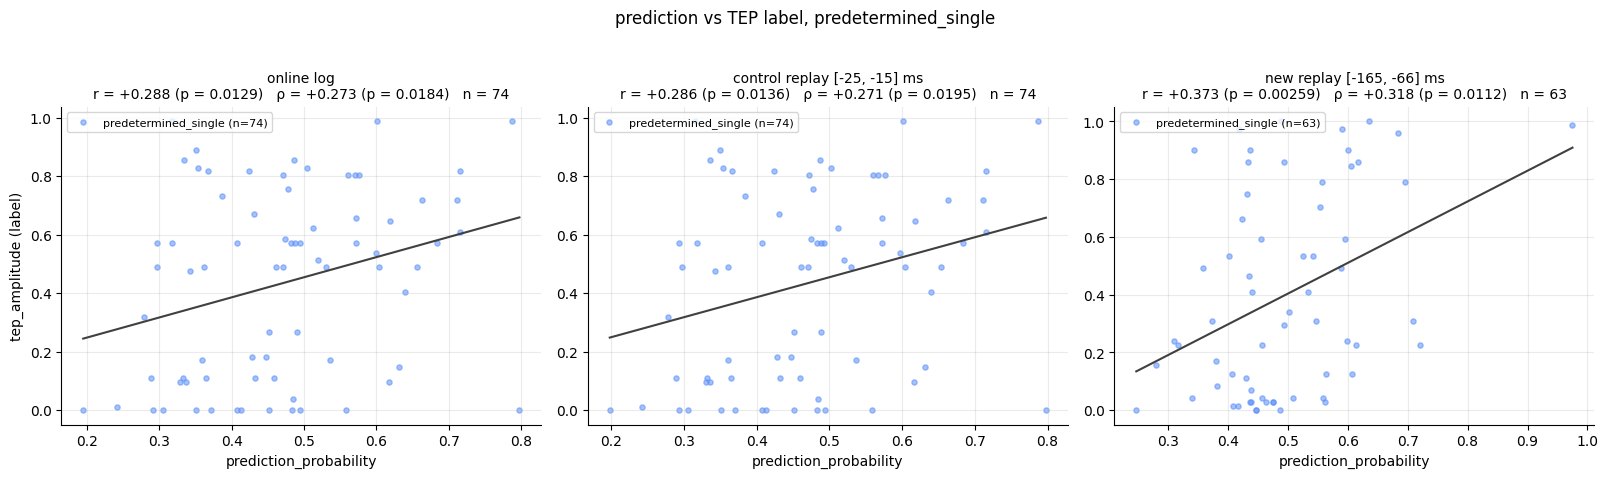

In [52]:
CORR = []


def corr_figure(title, ycol, ylabel, condition=None):
    fig, axes = plt.subplots(1, len(SOURCES), figsize=(5.4 * len(SOURCES), 4.6), squeeze=False)
    for ax, src in zip(axes[0], SOURCES):
        d = PERF[src] if condition is None else PERF[src][PERF[src].condition == condition]
        d = d.dropna(subset=["p", ycol])
        for cond, color in CONDITION_COLORS.items():
            dc = d[d.condition == cond]
            if len(dc):
                ax.scatter(dc.p, dc[ycol], s=14, alpha=0.55, color=color, label=f"{cond} (n={len(dc)})")
        if len(d) >= 3:
            r, p_r = stats.pearsonr(d.p, d[ycol])
            rho, p_rho = stats.spearmanr(d.p, d[ycol])
            b1, b0 = np.polyfit(d.p, d[ycol], 1)
            xs = np.linspace(d.p.min(), d.p.max(), 20)
            ax.plot(xs, b0 + b1 * xs, color="0.25", lw=1.5)
            ax.set_title(f"{source_label(src)}\nr = {r:+.3f} (p = {p_r:.3g})   ρ = {rho:+.3f} (p = {p_rho:.3g})   "
                         f"n = {len(d)}", fontsize=10)
            CORR.append({"analysis": title, "source": src, "n": len(d), "r": r, "p (r)": p_r,
                         "rho": rho, "p (rho)": p_rho})
        else:
            ax.set_title(f"{source_label(src)}\nfewer than 3 trials", fontsize=10)
        ax.set_xlabel("prediction_probability")
        ax.legend(fontsize=8, loc="upper left")
    axes[0][0].set_ylabel(ylabel)
    fig.suptitle(title, y=1.03)
    fig.tight_layout()
    plt.show()


corr_figure("prediction vs TEP label, predetermined_single", "label", "tep_amplitude (label)",
            condition="predetermined_single")

### 7.1b Predictions vs raw TEP amplitude, `predetermined_single`

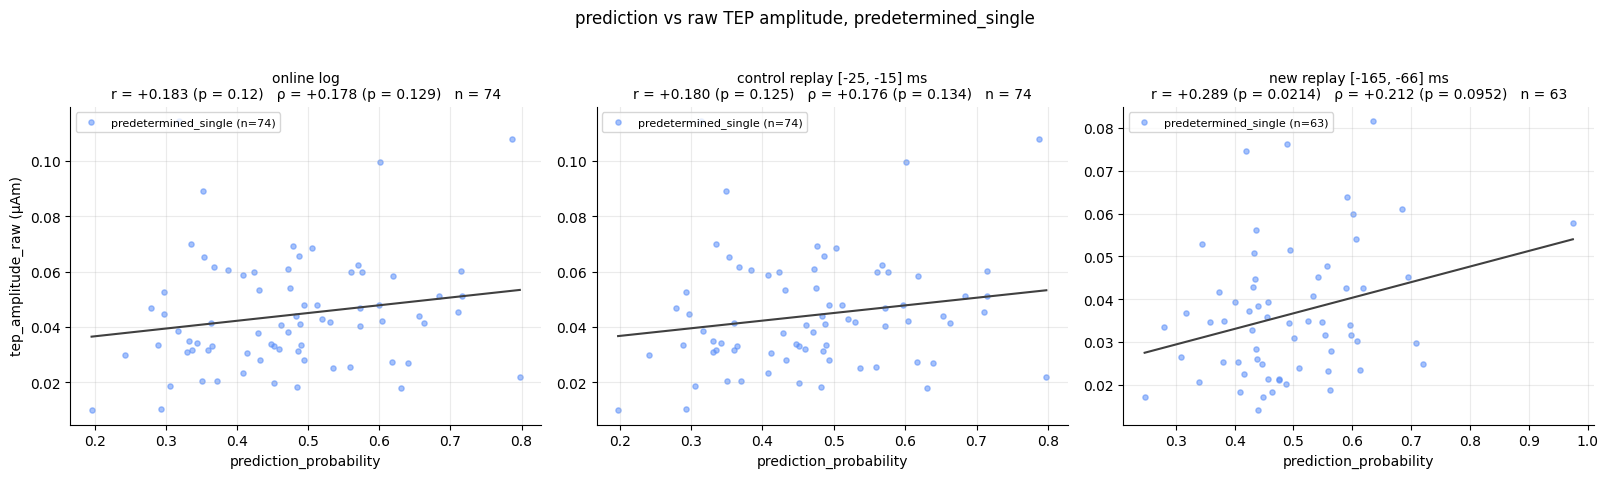

In [53]:
corr_figure("prediction vs raw TEP amplitude, predetermined_single", "raw", "tep_amplitude_raw (µAm)",
            condition="predetermined_single")

### 7.1c Predictions vs TEP label, all single pulses

`prime_single_pulse` (forced included in the replays) and `predetermined_single` together.

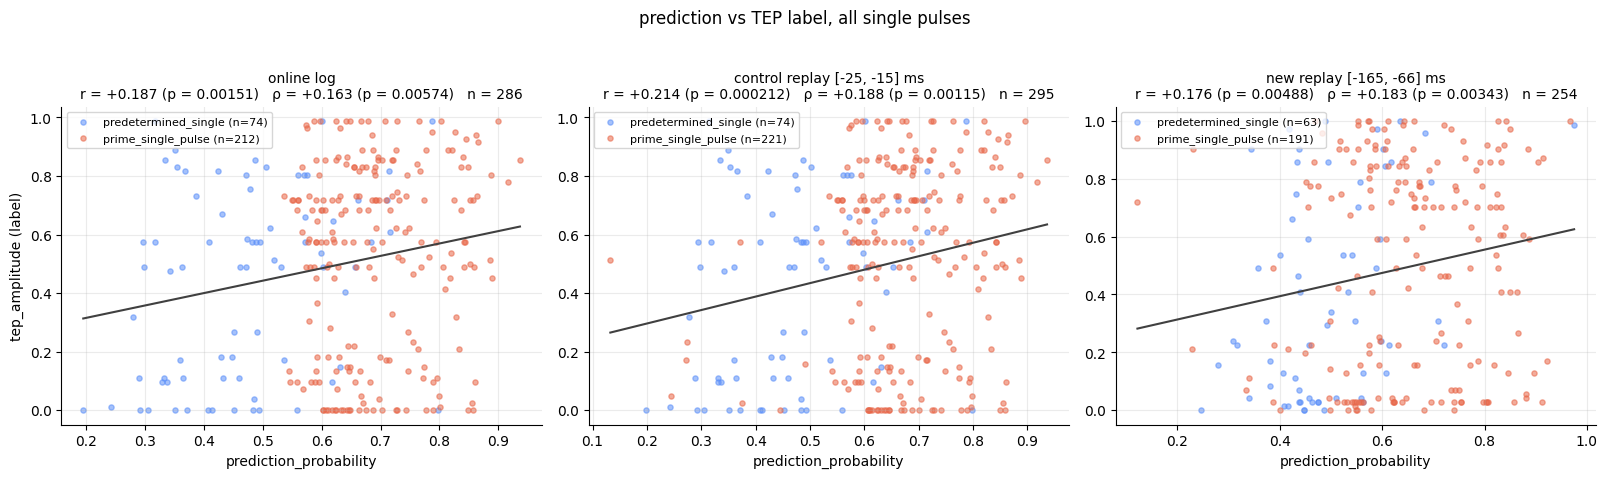

In [54]:
corr_figure("prediction vs TEP label, all single pulses", "label", "tep_amplitude (label)")

### 7.1d Per intervention block

The correlation of 7.1c per block. Each prediction is made before its trial is used for finetuning, so the
per-block values show whether the model's predictions track the label better as it adapts. About 80 single
pulses per block, so each value is noisy.

n                    r                   rho              
source  control   new online control    new online control    new online
block                                                                   
block 1    70.0  64.0   69.0   0.017  0.041 -0.040   0.011  0.050 -0.016
block 2    74.0  66.0   72.0   0.060  0.073  0.045   0.125  0.014  0.104
block 3    73.0  54.0   69.0   0.446  0.348  0.381   0.403  0.311  0.358
block 4    78.0  70.0   76.0   0.263  0.166  0.299   0.220  0.232  0.231

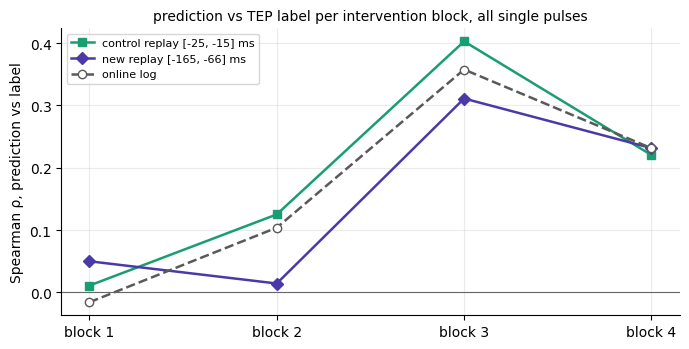

In [55]:
rows = []
for src in SOURCES:
    for block in BLOCKS:
        d = PERF[src][PERF[src].stage == block].dropna(subset=["p", "label"])
        r, rho = (stats.pearsonr(d.p, d.label)[0], stats.spearmanr(d.p, d.label)[0]) if len(d) >= 4 else (np.nan, np.nan)
        rows.append({"source": src, "block": block.replace("intervention_block_", "block "), "n": len(d),
                     "r": r, "rho": rho})
PER_BLOCK = pd.DataFrame(rows)
display(PER_BLOCK.pivot(index="block", columns="source", values=["n", "r", "rho"]).round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
for src in DRAW_ORDER:
    d, st = PER_BLOCK[PER_BLOCK.source == src], SOURCE_STYLE[src]
    ax.plot(d.block, d.rho, color=st["color"], ls=st["ls"], marker=st["marker"], mfc=st["mfc"], lw=1.8,
            label=source_label(src))
ax.axhline(0, color="0.4", lw=0.8)
ax.set_ylabel("Spearman ρ, prediction vs label")
ax.set_title("prediction vs TEP label per intervention block, all single pulses", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

#### Only `predetermined_single`

The same per-block correlation on the unselected trials only. These were not chosen by the online model, so their
predictions are not range-restricted. About 20 per block, so each value is noisier still.

n                    r                   rho              
source  control   new online control    new online control    new online
block                                                                   
block 1    19.0  16.0   19.0  -0.155  0.439 -0.156   0.001  0.520 -0.013
block 2    17.0  13.0   17.0   0.185  0.093  0.188   0.097  0.088  0.097
block 3    19.0  15.0   19.0   0.330 -0.042  0.332   0.303  0.013  0.303
block 4    19.0  19.0   19.0   0.229  0.365  0.236   0.256  0.220  0.285

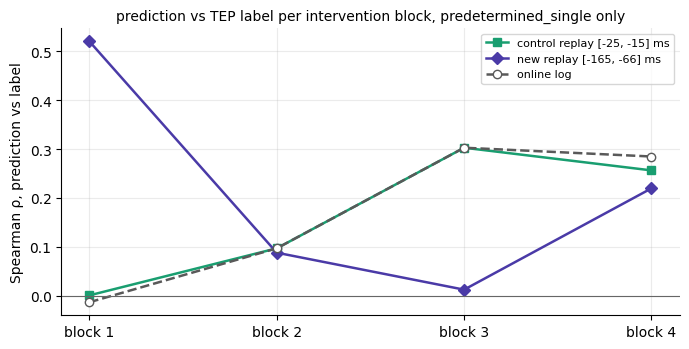

In [56]:
rows = []
for src in SOURCES:
    for block in BLOCKS:
        d = PERF[src][(PERF[src].stage == block) & (PERF[src].condition == "predetermined_single")]
        d = d.dropna(subset=["p", "label"])
        r, rho = (stats.pearsonr(d.p, d.label)[0], stats.spearmanr(d.p, d.label)[0]) if len(d) >= 4 else (np.nan, np.nan)
        rows.append({"source": src, "block": block.replace("intervention_block_", "block "), "n": len(d),
                     "r": r, "rho": rho})
PER_BLOCK_PRED = pd.DataFrame(rows)
display(PER_BLOCK_PRED.pivot(index="block", columns="source", values=["n", "r", "rho"]).round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
for src in DRAW_ORDER:
    d, st = PER_BLOCK_PRED[PER_BLOCK_PRED.source == src], SOURCE_STYLE[src]
    ax.plot(d.block, d.rho, color=st["color"], ls=st["ls"], marker=st["marker"], mfc=st["mfc"], lw=1.8,
            label=source_label(src))
ax.axhline(0, color="0.4", lw=0.8)
ax.set_ylabel("Spearman ρ, prediction vs label")
ax.set_title("prediction vs TEP label per intervention block, predetermined_single only", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8 · Out-of-sample test

The four evaluation blocks (t0, t15, t30, t60; run order 1–4 of
`trials_evaluation_<k>.csv`, the time points inferred from that order) are open-loop: PRIME did not select these
trials and never trained on them. For each source:

- **TEP**: raw dipole amplitude from the source's own preprocessing and dipole (online: the stored bundle and
  dipole with the online baseline; arms: their replayed calibration);
- **prediction window**: `_pre_raw` through the source's `preprocess_pre()`;
- **models**: the source's checkpoints after calibration and after each intervention block.

Per checkpoint: AUC of the prediction for high vs low TEP (split at the median within each block), pooled over the
four blocks, with a two-sided Mann–Whitney p; Spearman ρ between the prediction and the TEP percentile within its
block; and the mean prediction, which shows score drift. AUC 0.5 means no discrimination.

online log: 400 trials, 343 with a TEP, 390 with a prediction window; checkpoints: ['after calibration', 'after block 1', 'after block 2', 'after block 3', 'after block 4'] (17 s)
control replay [-25, -15] ms: 400 trials, 343 with a TEP, 390 with a prediction window; checkpoints: ['after calibration', 'after block 1', 'after block 2', 'after block 3', 'after block 4'] (18 s)
new replay [-165, -66] ms: 400 trials, 302 with a TEP, 385 with a prediction window; checkpoints: ['after calibration', 'after block 1', 'after block 2', 'after block 3', 'after block 4'] (17 s)


n    AUC  p (AUC)    rho  p (rho)  mean p
source  checkpoint                                                    
online  after calibration  336  0.534    0.284  0.051    0.352   0.641
        after block 1      336  0.511    0.724  0.009    0.868   0.500
        after block 2      336  0.499    0.971 -0.003    0.957   0.438
        after block 3      336  0.527    0.396  0.076    0.167   0.409
        after block 4      336  0.524    0.445  0.097    0.077   0.374
control after calibration  336  0.534    0.284  0.051    0.352   0.641
        after block 1      336  0.511    0.717  0.009    0.864   0.500
        after block 2      336  0.499    0.985 -0.002    0.969   0.438
        after block 3      336  0.528    0.379  0.078    0.154   0.409
        after block 4      336  0.525    0.423  0.099    0.070   0.374
new     after calibration  299  0.418    0.014 -0.078    0.180   0.639
        after block 1      299  0.407    0.005 -0.106    0.068   0.516
        after block 2      299  0.415    0.011 -0.084    0.146   0.457
        after block 3      299  0.461    0.242 -0.002    0.971   0.438
        after block 4      299  0.485    0.661  0.051    0.383   0.390

AUC per block:


block                         t0    t15    t30    t60
source  checkpoint                                   
online  after calibration  0.613  0.483  0.518  0.489
        after block 1      0.539  0.485  0.499  0.498
        after block 2      0.510  0.449  0.446  0.568
        after block 3      0.540  0.511  0.537  0.510
        after block 4      0.533  0.484  0.554  0.520
control after calibration  0.613  0.483  0.518  0.489
        after block 1      0.538  0.487  0.500  0.501
        after block 2      0.510  0.449  0.447  0.568
        after block 3      0.537  0.515  0.536  0.507
        after block 4      0.535  0.485  0.554  0.521
new     after calibration  0.449  0.394  0.397  0.414
        after block 1      0.402  0.420  0.394  0.417
        after block 2      0.394  0.470  0.384  0.408
        after block 3      0.444  0.538  0.389  0.444
        after block 4      0.447  0.554  0.457  0.481

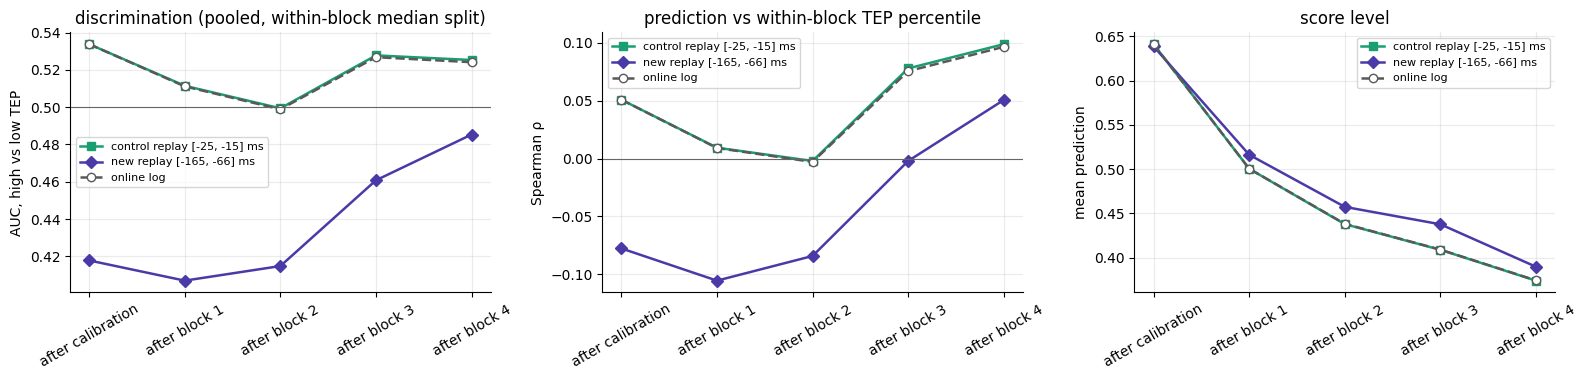

In [57]:
CHECKPOINTS = [("after calibration", "classifier_after_calibration.pt")] + [
    (b.replace("intervention_block_", "after block "), f"classifier_after_trial_{BLOCK_END[b]}.pt") for b in BLOCKS]
BLOCK_LABELS = {"evaluation_1": "t0", "evaluation_2": "t15", "evaluation_3": "t30",
                "evaluation_4": "t60"}
OOS_SOURCES = {"online": dict(pp=ONLINE["pp"], fitter=ONLINE["fitter"], dir=ONLINE_DIR)}
OOS_SOURCES.update({name: dict(pp=CALIB[name]["pp"], fitter=CALIB[name]["fitter"], dir=ARMS[name]["dir"])
                    for name in ARMS})

OOS = {}
for src, s in OOS_SOURCES.items():
    t0, rows, windows = time.time(), [], []
    for r in OPEN_TRIALS.itertuples():
        if not all((ONLINE_DIR / f"{r.stem}_{kind}_raw.npy").is_file() for kind in ("pre", "post")):
            continue
        x, t = post_buffer(r.stem, s["pp"]._post_initial_tmin)
        post = s["pp"].preprocess_post(x, t)
        pre, reason, _ = pre_from_raw(s["pp"], r.stem)
        rows.append({"stem": r.stem, "block": BLOCK_LABELS.get(r.block, r.block),
                     "amplitude": s["fitter"].fit_trial(post) if post is not None else np.nan,
                     "post_reject_reason": s["pp"].last_post_reject_reason, "pre_reject_reason": reason})
        windows.append(pre)
    df = pd.DataFrame(rows)
    ok = np.array([w is not None for w in windows], dtype=bool)
    for label, fname in CHECKPOINTS:
        if ok.any() and (s["dir"] / fname).is_file():
            p = np.full(len(df), np.nan)
            p[ok] = checkpoint_model(s["dir"] / fname).predict_batch(np.stack([w for w in windows if w is not None]))
            df[label] = p
    OOS[src] = df
    print(f"{source_label(src)}: {len(df)} trials, {int(df.amplitude.notna().sum())} with a TEP, {int(ok.sum())} "
          f"with a prediction window; checkpoints: {[c for c, _ in CHECKPOINTS if c in df]} ({time.time() - t0:.0f} s)")


def oos_metrics(d, col):
    d = d.dropna(subset=["amplitude", col])
    if len(d) < 6 or d.block.nunique() == 0:
        return {"n": len(d), "AUC": np.nan, "p (AUC)": np.nan, "rho": np.nan, "p (rho)": np.nan,
                "mean p": d[col].mean() if len(d) else np.nan}
    high = d.groupby("block").amplitude.transform(lambda a: a > a.median()).astype(bool)
    pct = d.groupby("block").amplitude.rank(pct=True)
    hi, lo = d.loc[high, col], d.loc[~high, col]
    u = stats.mannwhitneyu(hi, lo, alternative="two-sided")
    rho, p_rho = stats.spearmanr(d[col], pct)
    return {"n": len(d), "AUC": u.statistic / (len(hi) * len(lo)), "p (AUC)": u.pvalue, "rho": rho,
            "p (rho)": p_rho, "mean p": d[col].mean()}


rows, block_rows = [], []
for src, df in OOS.items():
    for label, _ in CHECKPOINTS:
        if label not in df:
            continue
        rows.append({"source": src, "checkpoint": label, **oos_metrics(df, label)})
        for block in df.block.unique():
            block_rows.append({"source": src, "checkpoint": label, "block": block,
                               **oos_metrics(df[df.block == block], label)})
OOS_TABLE = pd.DataFrame(rows).set_index(["source", "checkpoint"])
OOS_BLOCKS = pd.DataFrame(block_rows)
display(OOS_TABLE.round(3))
if len(OOS_BLOCKS):
    print("AUC per block:")
    auc = OOS_BLOCKS.pivot_table(index=["source", "checkpoint"], columns="block", values="AUC", dropna=False)
    present = set(zip(OOS_BLOCKS.source, OOS_BLOCKS.checkpoint))
    order = [(src, c) for src in OOS for c, _ in CHECKPOINTS if (src, c) in present]
    display(auc.loc[order, [b for b in BLOCK_LABELS.values() if b in auc.columns]].round(3))

CKPT_X = {c: i for i, (c, _) in enumerate(CHECKPOINTS)}      # fixed x position per checkpoint
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
for src in [x for x in DRAW_ORDER if x in OOS_TABLE.index.get_level_values(0)]:
    st, d = SOURCE_STYLE[src], OOS_TABLE.loc[src]
    for ax, col in zip(axes, ("AUC", "rho", "mean p")):
        ax.plot([CKPT_X[c] for c in d.index], d[col], color=st["color"], ls=st["ls"], marker=st["marker"],
                mfc=st["mfc"], lw=1.8, label=source_label(src))
axes[0].axhline(0.5, color="0.4", lw=0.8)
axes[1].axhline(0, color="0.4", lw=0.8)
axes[0].set(ylabel="AUC, high vs low TEP", title="discrimination (pooled, within-block median split)")
axes[1].set(ylabel="Spearman ρ", title="prediction vs within-block TEP percentile")
axes[2].set(ylabel="mean prediction", title="score level")
for ax in axes:
    ax.set_xticks(list(CKPT_X.values()))
    ax.set_xticklabels(list(CKPT_X), rotation=30)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 8.1 Prediction vs raw TEP amplitude

The scatter of 7.1b for the open-loop evaluation trials: prediction against `tep_amplitude_raw` (the source's own
free-orientation dipole amplitude), one panel per source, with Pearson r, Spearman ρ and a least-squares line over
all trials pooled. Points are coloured by evaluation block, so level shifts between t0 and t60 are visible. These
trials were never selected by the model or finetuned on. The plot uses the model of one checkpoint,
`OOS_PLOT_CHECKPOINT` (default: after the last intervention block). The raw amplitudes are not detrended and not on a
common scale across sources.

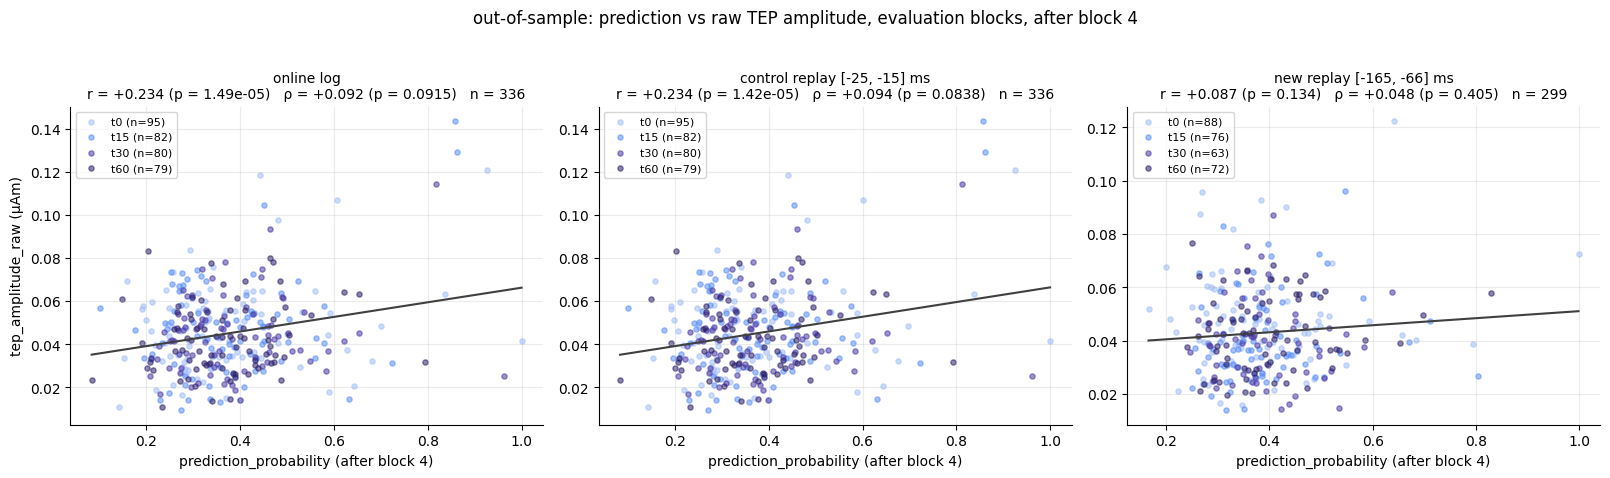

,,n,r,p (r),rho,p (rho)
source,checkpoint,,,,,
online,after block 4,336,0.2338,0.0000,0.0922,0.0915
control,after block 4,336,0.2344,0.0000,0.0945,0.0838
new,after block 4,299,0.0868,0.1344,0.0484,0.4046


In [58]:
OOS_PLOT_CHECKPOINT = CHECKPOINTS[-1][0]          # a label from CHECKPOINTS, e.g. "after calibration" or "after block 2"
BLOCK_COLORS = dict(zip(BLOCK_LABELS.values(), ["#a3bffa", "#5b8ff9", "#4a3aa7", "#2b1f6b"]))   # t0 ... t60, light to dark


def oos_scatter(ckpt):
    srcs = [s for s in SOURCES if s in OOS and ckpt in OOS[s]]
    fig, axes = plt.subplots(1, len(srcs), figsize=(5.4 * len(srcs), 4.6), squeeze=False)
    rows = []
    for ax, src in zip(axes[0], srcs):
        d = OOS[src].dropna(subset=[ckpt, "amplitude"])
        for block in d.block.unique():
            db = d[d.block == block]
            ax.scatter(db[ckpt], db.amplitude, s=14, alpha=0.55, color=BLOCK_COLORS.get(block, "0.5"),
                       label=f"{block} (n={len(db)})")
        if len(d) >= 3:
            r, p_r = stats.pearsonr(d[ckpt], d.amplitude)
            rho, p_rho = stats.spearmanr(d[ckpt], d.amplitude)
            b1, b0 = np.polyfit(d[ckpt], d.amplitude, 1)
            xs = np.linspace(d[ckpt].min(), d[ckpt].max(), 20)
            ax.plot(xs, b0 + b1 * xs, color="0.25", lw=1.5)
            ax.set_title(f"{source_label(src)}\nr = {r:+.3f} (p = {p_r:.3g})   ρ = {rho:+.3f} (p = {p_rho:.3g})   "
                         f"n = {len(d)}", fontsize=10)
            rows.append({"source": src, "checkpoint": ckpt, "n": len(d), "r": r, "p (r)": p_r,
                         "rho": rho, "p (rho)": p_rho})
        else:
            ax.set_title(f"{source_label(src)}\nfewer than 3 trials", fontsize=10)
        ax.set_xlabel(f"prediction_probability ({ckpt})")
        ax.legend(fontsize=8, loc="upper left")
    axes[0][0].set_ylabel("tep_amplitude_raw (µAm)")
    fig.suptitle(f"out-of-sample: prediction vs raw TEP amplitude, evaluation blocks, {ckpt}", y=1.03)
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(rows).set_index(["source", "checkpoint"])


OOS_SCATTER = oos_scatter(OOS_PLOT_CHECKPOINT)
display(OOS_SCATTER.round(4))

## Summary

The main numbers of sections 5–8 in one place. The tables are saved in the new arm's folder
(`calibration_comparison.csv`, `rejection_comparison.csv`, `prediction_correlations.csv`, `out_of_sample.csv`,
`out_of_sample_by_block.csv`).

In [59]:
out = ARMS["new"]["dir"]
print("Calibration")
for src in SOURCES:
    b, d = CAL_SRC[src]["bundle"], DIPOLES[src]
    print(f"  {source_label(src):34s} kept {len(b['trials_kept']):3d} "
          f"(ocular {len(b['trials_dropped']['ocular'])}, pre MAD {len(b['trials_dropped']['qc'])}, "
          f"post MAD {len(b['trials_dropped']['post'])}); bad channels {', '.join(map(str, b['bad_channels'])) or '-'}; "
          f"dipole vertex {d['vertex']}, {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms")
display(DIPOLE_DIFF)

print("Rejections of the single-pulse trials")
display(REJECTIONS)

CORR_TABLE = pd.DataFrame(CORR).set_index(["analysis", "source"])
print("Prediction vs TEP (section 7)")
display(CORR_TABLE.round(4))

print("Out-of-sample (section 8)")
display(OOS_TABLE.round(3))

CAL_REJECTIONS.to_csv(out / "calibration_rejections.csv")
REJECTIONS.to_csv(out / "rejection_comparison.csv")
CORR_TABLE.to_csv(out / "prediction_correlations.csv")
PER_BLOCK.to_csv(out / "prediction_correlations_by_block.csv", index=False)
OOS_TABLE.to_csv(out / "out_of_sample.csv")
OOS_BLOCKS.to_csv(out / "out_of_sample_by_block.csv", index=False)
if not CHECK.empty:
    CHECK.to_csv(out / "prediction_check_online_checkpoints.csv", index=False)
print(f"tables saved to {out}")

Calibration
  online log                         kept 107 (ocular 13, pre MAD 4, post MAD 1); bad channels C3, CP3, T8; dipole vertex 4641, 39-42 ms
  control replay [-25, -15] ms       kept 107 (ocular 13, pre MAD 4, post MAD 1); bad channels C3, CP3, T8; dipole vertex 4641, 39-42 ms
  new replay [-165, -66] ms          kept  96 (ocular 25, pre MAD 3, post MAD 1); bad channels C3, CP3, T8; dipole vertex 5910, 40-45 ms


,vertices,distance (mm),orientation angle (°),windows (ms),window start shift (ms),shared samples
comparison,,,,,,
control vs online,4641 vs 4641,0.0,0.0,39-42 vs 39-42,0.0,4
new vs online,5910 vs 4641,24.4,16.8,40-45 vs 39-42,1.0,3
new vs control,5910 vs 4641,24.4,16.8,40-45 vs 39-42,1.0,3


Rejections of the single-pulse trials


,single pulses,post rejected online,post rejected replay,only online,only replay,pre rejected replay
arm,,,,,,
control,320,25,25,0,0,0
new,320,25,66,5,46,0


Prediction vs TEP (section 7)


n       r   p (r)     rho  p (rho)
analysis                                              source                                       
prediction vs TEP label, predetermined_single         online    74  0.2878  0.0129  0.2734   0.0184
                                                      control   74  0.2858  0.0136  0.2711   0.0195
                                                      new       63  0.3732  0.0026  0.3177   0.0112
prediction vs raw TEP amplitude, predetermined_single online    74  0.1825  0.1196  0.1783   0.1286
                                                      control   74  0.1798  0.1254  0.1757   0.1344
                                                      new       63  0.2894  0.0214  0.2121   0.0952
prediction vs TEP label, all single pulses            online   286  0.1868  0.0015  0.1630   0.0057
                                                      control  295  0.2140  0.0002  0.1884   0.0012
                                                      new      254  0.1761  0.0049  0.1830   0.0034

Out-of-sample (section 8)


n    AUC  p (AUC)    rho  p (rho)  mean p
source  checkpoint                                                    
online  after calibration  336  0.534    0.284  0.051    0.352   0.641
        after block 1      336  0.511    0.724  0.009    0.868   0.500
        after block 2      336  0.499    0.971 -0.003    0.957   0.438
        after block 3      336  0.527    0.396  0.076    0.167   0.409
        after block 4      336  0.524    0.445  0.097    0.077   0.374
control after calibration  336  0.534    0.284  0.051    0.352   0.641
        after block 1      336  0.511    0.717  0.009    0.864   0.500
        after block 2      336  0.499    0.985 -0.002    0.969   0.438
        after block 3      336  0.528    0.379  0.078    0.154   0.409
        after block 4      336  0.525    0.423  0.099    0.070   0.374
new     after calibration  299  0.418    0.014 -0.078    0.180   0.639
        after block 1      299  0.407    0.005 -0.106    0.068   0.516
        after block 2      299  0.415    0.011 -0.084    0.146   0.457
        after block 3      299  0.461    0.242 -0.002    0.971   0.438
        after block 4      299  0.485    0.661  0.051    0.383   0.390

tables saved to D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_-165_-66ms
